# Physics-Informed Masked Multi-Task Learning (PIM-MTL)
## End-to-End Concrete Strength Prediction, Full EDA, Training & Comparative Analysis Pipeline

**Dataset:** ConcreteXAI (4,420 multivariate experimental concrete specimens)  
**Target Domain:** Multi-Task Mechanical Strength Prediction under Asymmetric Missingness:
- $C_s$: Compressive Strength (MPa) — 100% observed ($N=4,420$)
- $T_s$: Splitting Tensile Strength (MPa) — 78.3% observed ($N=3,460$, 21.7% missing)
- $F_s$: Flexural Strength / Modulus of Rupture (MPa) — 39.8% observed ($N=1,760$, 60.2% missing)

---

### Core Objectives of this Notebook:
1. **Full Exploratory Data Analysis (EDA):** In-depth structural, univariate, bivariate, and correlation analysis, target coverage profile, and ground-truth mechanical ratio distributions compared against ACI 318 design code bounds.
2. **Leakage-Free Preprocessing:** Fold-isolated 80/20 train/test partition, One-Hot Encoding for mix designs, RobustScaler for skewed non-destructive test proxies (`Er_ohm-cm`), and observation mask tensors.
3. **PIM-MTL Architecture & Differentiable Physics Loss:** Shared 3-layer representation trunk (`PIM_MTL_Net`) with gradient gating for missing values and two-sided quadratic hinge penalties for civil engineering ratio envelopes ($R_t \in [0.06, 0.18]$ and $R_f \in [0.08, 0.25]$).
4. **Structured Model Training:** Full 60-epoch training with Adam, Cosine Annealing learning rate schedule, gradient norm clipping, and validation loss tracking.
5. **Model & Artifact Persistence:** Saving the trained PyTorch checkpoint (`models/pim_mtl_model.pt`) and preprocessor (`models/preprocessor.joblib`).
6. **Diagnostic & Comparison Plots:** High-resolution visualizations displayed inline and automatically saved to disk (`figures/` directory):
   - Training convergence curves (Total loss, Data MSE, Physics penalty)
   - Parity plots (Predicted vs. Actual) for $C_s, T_s, F_s$
   - Residual distribution histograms and bias analysis
   - Ground Truth vs. Predicted mechanical strength ratio comparisons
   - Multi-metric target performance and relative error analysis bar charts
   - Physical compliance and feasibility audit
7. **Final Results Persistence to CSV:** Exporting comprehensive evaluation metrics and specimen predictions into clean CSV files (`final_evaluation_results.csv`, `final_test_predictions.csv`).


## 1. Environment Setup & Configuration
We import standard scientific libraries, configure deterministic random seeds across Python, NumPy, and PyTorch (for strict reproducibility), create output directories for saved models, figures, and CSV results, and verify the compute device (CUDA GPU / CPU).


In [14]:
import os
import sys
import random
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Add parent directory to path to import project modules
current_dir = os.getcwd()
if os.path.basename(current_dir) == "notebooks":
    project_root = os.path.abspath(os.path.join(current_dir, ".."))
else:
    project_root = os.path.abspath(current_dir)

if project_root not in sys.path:
    sys.path.insert(0, project_root)

from utils.models import PIM_MTL_Net
from utils.losses import PIM_MTL_Loss

# Global Configuration and Deterministic Seed
SEED = 42
def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

# Create Output Directories for Models, Figures, and CSV Results
MODELS_DIR = os.path.join(project_root, "models")
FIGURES_DIR = os.path.join(project_root, "figures")
RESULTS_DIR = os.path.join(project_root, "results")

for d in [MODELS_DIR, FIGURES_DIR, RESULTS_DIR]:
    os.makedirs(d, exist_ok=True)

# Plotting aesthetics
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 11

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Environment Initialized Successfully!")
print(f"Project Root Directory : {project_root}")
print(f"Artifacts Directories  : models/ | figures/ | results/")
print(f"Compute Device         : {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")


Environment Initialized Successfully!
Project Root Directory : c:\Users\jeetu\projects\Capstone\3rdYearsem5
Artifacts Directories  : models/ | figures/ | results/
Compute Device         : cuda (NVIDIA GeForce RTX 4050 Laptop GPU)


## 2. Data Loading & Schema Inspection
We load the `Data.csv` dataset, strip any surrounding whitespace from categorical attributes, define the schema constants, and review the structural dimensions and column types.


In [15]:
# Define Schema Constants
CATEGORICAL_COLS = ["Type_of_cement", "Brand", "Additives", "Type_of_aggregates"]
NUMERICAL_COLS = ["Design_Fc_Mpa", "Curing_age_days", "Er_ohm-cm", "UPV_m/s"]
TARGET_COLS = ["Cs_Mpa", "Ts_Mpa", "Fs_Mpa"]

data_path = os.path.join(project_root, "Data.csv")
if not os.path.exists(data_path):
    raise FileNotFoundError(f"Dataset file not found at: {data_path}")

df = pd.read_csv(data_path)

# Clean categorical whitespace
for col in CATEGORICAL_COLS:
    df[col] = df[col].astype(str).str.strip()

print(f"Dataset Dimensions: {df.shape[0]:,} specimens across {df.shape[1]} columns")
print("\n--- Column Schema Overview ---")
print(f"Categorical Features ({len(CATEGORICAL_COLS)}): {CATEGORICAL_COLS}")
print(f"Numerical Predictors ({len(NUMERICAL_COLS)}): {NUMERICAL_COLS}")
print(f"Mechanical Targets   ({len(TARGET_COLS)}): {TARGET_COLS}")

# Display First 5 Samples
display(df.head(5))


Dataset Dimensions: 4,420 specimens across 12 columns

--- Column Schema Overview ---
Categorical Features (4): ['Type_of_cement', 'Brand', 'Additives', 'Type_of_aggregates']
Numerical Predictors (4): ['Design_Fc_Mpa', 'Curing_age_days', 'Er_ohm-cm', 'UPV_m/s']
Mechanical Targets   (3): ['Cs_Mpa', 'Ts_Mpa', 'Fs_Mpa']


,id,Type_of_cement,Brand,Additives,Type_of_aggregates,Design_Fc_Mpa,Curing_age_days,Cs_Mpa,Ts_Mpa,Fs_Mpa,Er_ohm-cm,UPV_m/s
0,0,CPO 30R RS BRA,CEMEX,Opuntia_ficus_indica,Rounded,25,3,5.2154,0.5609,NaN,5.8654,2440.2989
1,1,CPO 30R RS BRA,CEMEX,Opuntia_ficus_indica,Rounded,25,3,5.1528,0.5727,NaN,5.9471,2417.9562
2,2,CPO 30R RS BRA,CEMEX,Opuntia_ficus_indica,Rounded,25,3,5.6877,0.5826,NaN,5.9965,2429.9277
3,3,CPO 30R RS BRA,CEMEX,Opuntia_ficus_indica,Rounded,25,3,5.1476,0.5910,NaN,5.8751,2435.0202
4,4,CPO 30R RS BRA,CEMEX,Opuntia_ficus_indica,Rounded,25,3,5.3406,0.5698,NaN,5.8654,2408.7969


### 2.1 Dataset Missingness Audit
In standard concrete engineering datasets, compressive strength is routine, while tensile and flexural tests are destructive and labor-intensive. Below, we tabulate the exact observed count, missing count, and missingness percentage across all features and target variables.


In [16]:
# Column-wise missingness audit table
missing_rows = []
for col in df.columns:
    if col == "id":
        continue
    n_obs = df[col].notna().sum()
    n_miss = df[col].isna().sum()
    pct_miss = (n_miss / len(df)) * 100.0
    dtype = str(df[col].dtype)
    col_type = "Target" if col in TARGET_COLS else ("Categorical" if col in CATEGORICAL_COLS else "Numerical")
    missing_rows.append({
        "Column": col,
        "Role": col_type,
        "Data Type": dtype,
        "Observed": n_obs,
        "Missing": n_miss,
        "Missingness (%)": f"{pct_miss:.2f}%",
        "Coverage (%)": f"{100.0 - pct_miss:.2f}%"
    })

audit_df = pd.DataFrame(missing_rows)
display(audit_df)


,Column,Role,Data Type,Observed,Missing,Missingness (%),Coverage (%)
0,Type_of_cement,Categorical,str,4420,0,0.00%,100.00%
1,Brand,Categorical,str,4420,0,0.00%,100.00%
2,Additives,Categorical,str,4420,0,0.00%,100.00%
3,Type_of_aggregates,Categorical,str,4420,0,0.00%,100.00%
4,Design_Fc_Mpa,Numerical,int64,4420,0,0.00%,100.00%
5,Curing_age_days,Numerical,int64,4420,0,0.00%,100.00%
6,Cs_Mpa,Target,float64,4420,0,0.00%,100.00%
7,Ts_Mpa,Target,float64,3460,960,21.72%,78.28%
8,Fs_Mpa,Target,float64,1760,2660,60.18%,39.82%
9,Er_ohm-cm,Numerical,float64,4420,0,0.00%,100.00%


## 3. Comprehensive Exploratory Data Analysis (EDA)
In this section, we conduct a thorough, structured visual exploration of the dataset in order:
1. **Target Observation Coverage Profile:** Stacked bar chart and multi-task observation regimes.
2. **Continuous Predictor Distributions & Outlier Analysis:** Density plots and boxplots highlighting the heavy skewness of electrical resistivity (`Er_ohm-cm`).
3. **Categorical Mix Design Distributions:** Frequency charts for cement types, manufacturers, admixtures, and aggregate morphology.
4. **Target Variables Distribution:** Empirical distributions for compressive, tensile, and flexural strengths.
5. **Ground Truth Mechanical Strength Ratios vs. ACI 318 Bounds:** Verification of tensile and flexural ratio clusters against civil engineering code envelopes ($R_t \in [0.06, 0.18]$ and $R_f \in [0.08, 0.25]$).
6. **Feature & Target Pearson Correlation Matrix:** Heatmap uncovering linear coupling.
7. **Bivariate Relationships:** Scatter plots demonstrating the physical dependence of strengths on Ultrasonic Pulse Velocity (UPV), curing maturity, and resistivity.

*All generated visualizations are saved at 300 DPI into the `figures/` directory.*


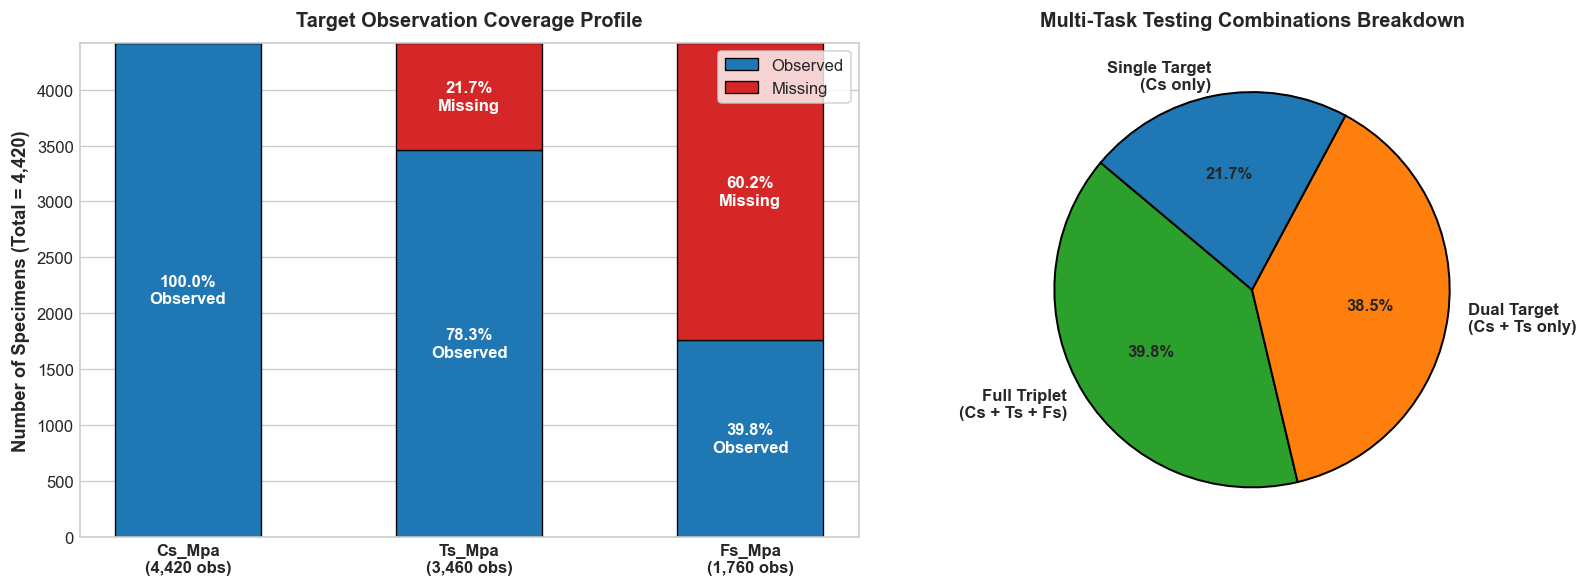

[SAVED] Target missingness profile saved to: c:\Users\jeetu\projects\Capstone\3rdYearsem5\figures\01_target_missingness_profile.png


In [17]:
# 1. Target Observation Coverage Profile
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1A: Stacked Bar Chart for Target Observability
obs_counts = [df[col].notna().sum() for col in TARGET_COLS]
miss_counts = [df[col].isna().sum() for col in TARGET_COLS]
x_indices = np.arange(len(TARGET_COLS))

axes[0].bar(x_indices, obs_counts, label="Observed", color="#1f77b4", width=0.52, edgecolor="black", linewidth=0.8)
axes[0].bar(x_indices, miss_counts, bottom=obs_counts, label="Missing", color="#d62728", width=0.52, edgecolor="black", linewidth=0.8)
axes[0].set_xticks(x_indices)
axes[0].set_xticklabels([f"{c}\n({obs_counts[i]:,} obs)" for i, c in enumerate(TARGET_COLS)], fontweight="bold")
axes[0].set_ylabel("Number of Specimens (Total = 4,420)", fontweight="bold")
axes[0].set_title("Target Observation Coverage Profile", fontweight="bold", pad=10)
axes[0].legend(loc="upper right", frameon=True)

for i in range(len(TARGET_COLS)):
    obs_pct = (obs_counts[i] / len(df)) * 100
    axes[0].text(i, obs_counts[i] / 2, f"{obs_pct:.1f}%\nObserved", ha="center", va="center", color="white", fontweight="bold", fontsize=10)
    if miss_counts[i] > 0:
        miss_pct = (miss_counts[i] / len(df)) * 100
        axes[0].text(i, obs_counts[i] + (miss_counts[i] / 2), f"{miss_pct:.1f}%\nMissing", ha="center", va="center", color="white", fontweight="bold", fontsize=10)

# Subplot 1B: Multi-Task Combination Breakdown
# Regimes: Complete (Cs+Ts+Fs), Semi-Complete (Cs+Ts only), Compressive Only (Cs only)
complete_triplet = (df["Cs_Mpa"].notna() & df["Ts_Mpa"].notna() & df["Fs_Mpa"].notna()).sum()
cs_ts_only = (df["Cs_Mpa"].notna() & df["Ts_Mpa"].notna() & df["Fs_Mpa"].isna()).sum()
cs_only = (df["Cs_Mpa"].notna() & df["Ts_Mpa"].isna() & df["Fs_Mpa"].isna()).sum()
regimes = ["Full Triplet\n(Cs + Ts + Fs)", "Dual Target\n(Cs + Ts only)", "Single Target\n(Cs only)"]
counts = [complete_triplet, cs_ts_only, cs_only]
colors = ["#2ca02c", "#ff7f0e", "#1f77b4"]

axes[1].pie(counts, labels=regimes, autopct="%1.1f%%", startangle=140, colors=colors,
            wedgeprops={"edgecolor": "black", "linewidth": 1.2}, textprops={"fontweight": "bold"})
axes[1].set_title("Multi-Task Testing Combinations Breakdown", fontweight="bold", pad=10)

plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "01_target_missingness_profile.png")
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"[SAVED] Target missingness profile saved to: {fig_path}")


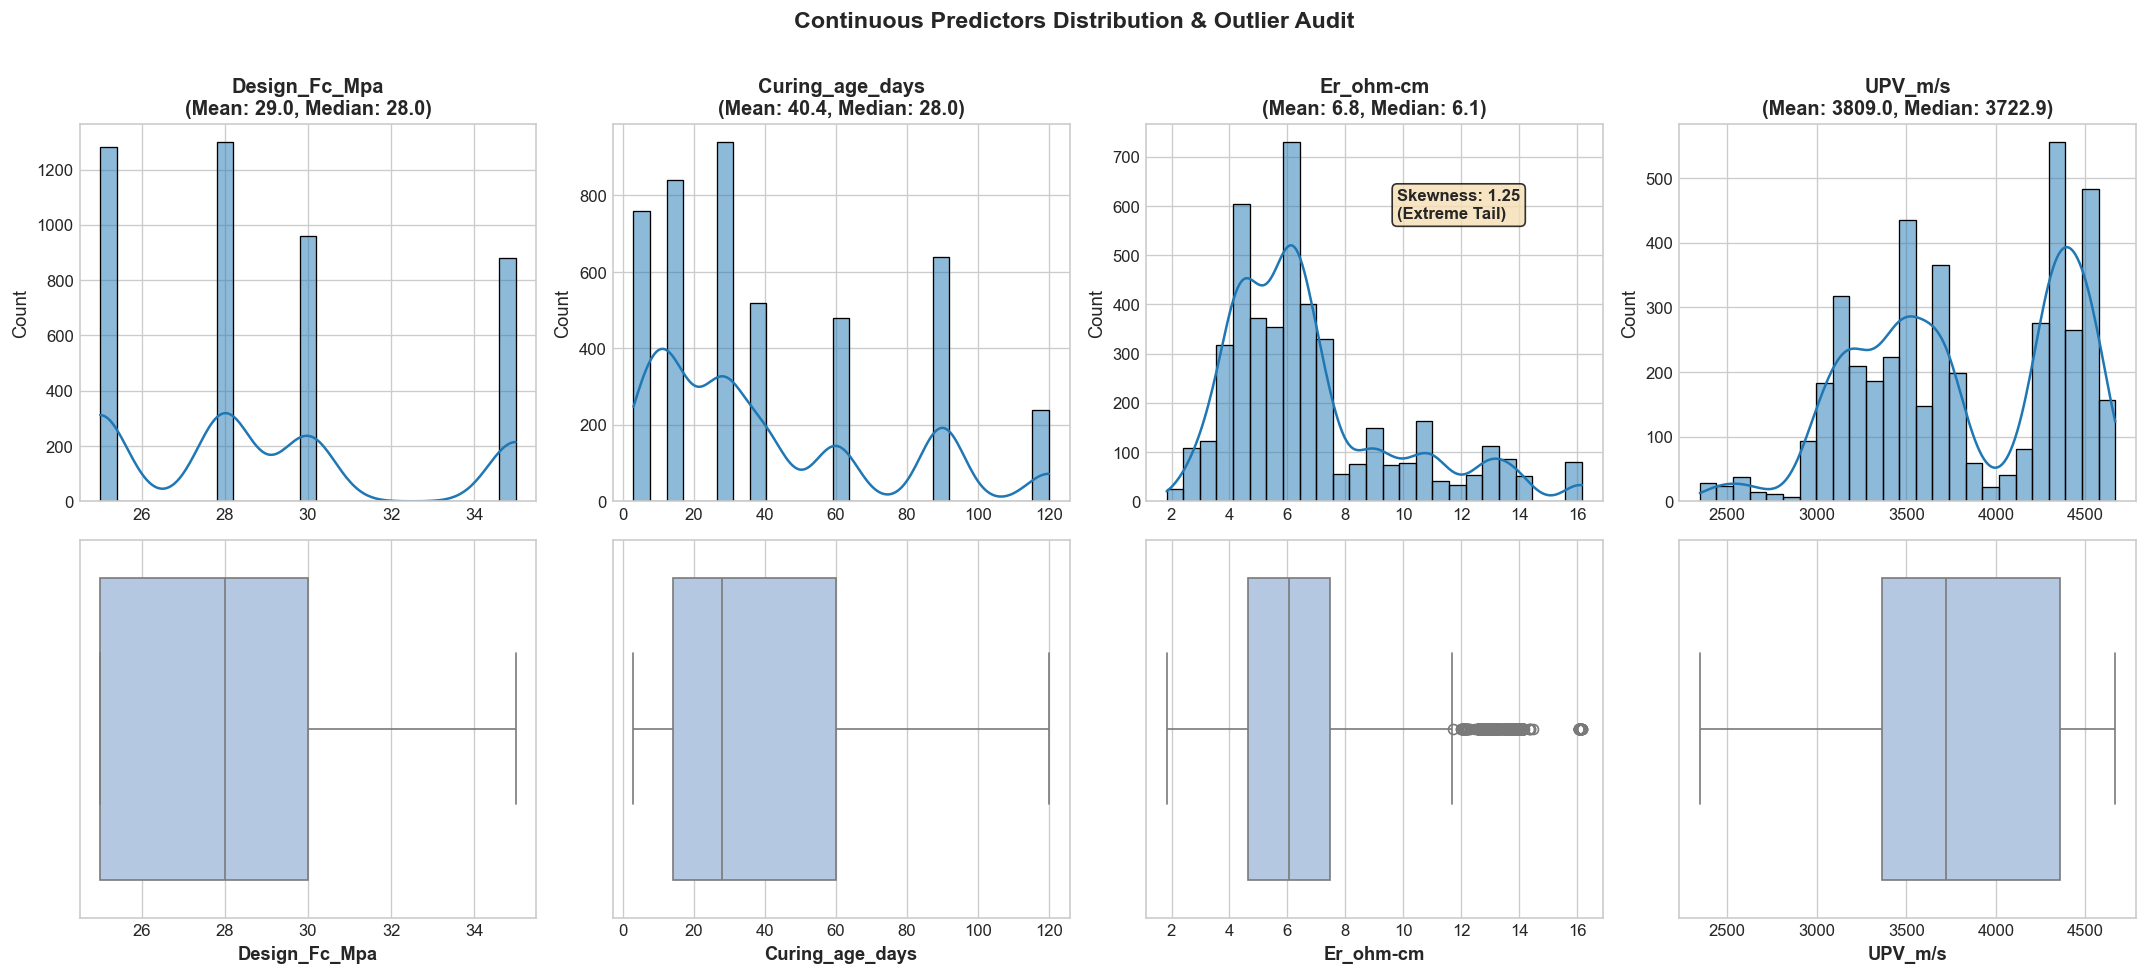

[SAVED] Continuous predictors distribution saved to: c:\Users\jeetu\projects\Capstone\3rdYearsem5\figures\02_continuous_features_distribution.png
[INSIGHT] Electrical Resistivity (Er_ohm-cm) exhibits extreme positive skewness, strongly validating the use of RobustScaler (median & IQR).


In [18]:
# 2. Continuous Predictor Univariate Distributions & Outlier Inspection
fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for idx, col in enumerate(NUMERICAL_COLS):
    data = df[col].dropna()
    # Row 0: Histogram + KDE
    sns.histplot(data, kde=True, ax=axes[0, idx], color="#1f77b4", edgecolor="black", bins=25)
    axes[0, idx].set_title(f"{col}\n(Mean: {data.mean():.1f}, Median: {data.median():.1f})", fontweight="bold")
    axes[0, idx].set_xlabel("")
    axes[0, idx].set_ylabel("Count")
    
    # Row 1: Boxplot to highlight skewness / outliers
    sns.boxplot(x=data, ax=axes[1, idx], color="#aec7e8", orient="h")
    axes[1, idx].set_xlabel(col, fontweight="bold")
    
    # Special annotation for Electrical Resistivity skewness
    if col == "Er_ohm-cm":
        skewness = data.skew()
        axes[0, idx].text(0.55, 0.75, f"Skewness: {skewness:.2f}\n(Extreme Tail)", transform=axes[0, idx].transAxes,
                          bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.8), fontweight="bold")

plt.suptitle("Continuous Predictors Distribution & Outlier Audit", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "02_continuous_features_distribution.png")
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"[SAVED] Continuous predictors distribution saved to: {fig_path}")
print("[INSIGHT] Electrical Resistivity (Er_ohm-cm) exhibits extreme positive skewness, strongly validating the use of RobustScaler (median & IQR).")


C:\Users\jeetu\AppData\Local\Temp\ipykernel_30168\3471340978.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.values, y=counts.index, ax=axes[r, c], palette=palette, edgecolor="black", linewidth=0.8)
C:\Users\jeetu\AppData\Local\Temp\ipykernel_30168\3471340978.py:8: UserWarning: The palette list has more values (10) than needed (4), which may not be intended.
  sns.barplot(x=counts.values, y=counts.index, ax=axes[r, c], palette=palette, edgecolor="black", linewidth=0.8)
C:\Users\jeetu\AppData\Local\Temp\ipykernel_30168\3471340978.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.values, y=counts.index, ax=axes[r, c], palette=palette, edgecolor="black", linewidth=0.8)

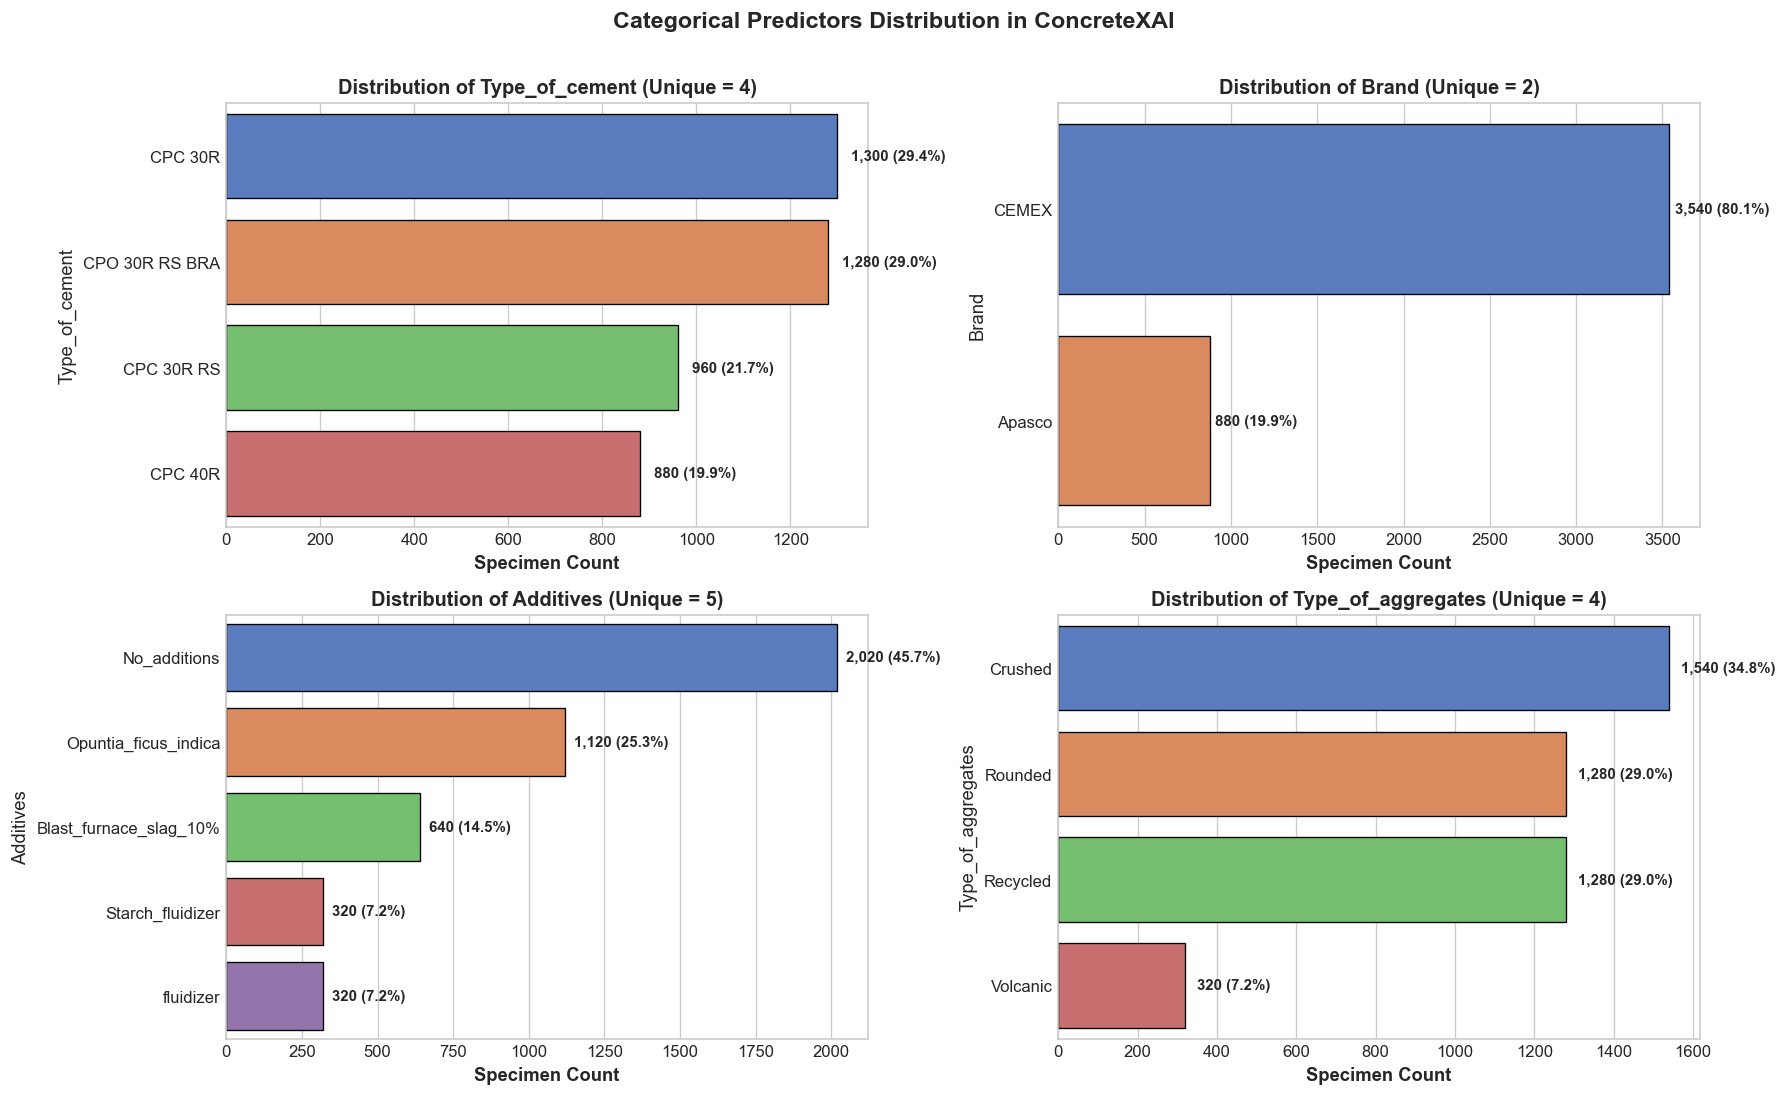

[SAVED] Categorical distributions saved to: c:\Users\jeetu\projects\Capstone\3rdYearsem5\figures\03_categorical_features_distribution.png


In [19]:
# 3. Categorical Mix Design Distributions
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
palette = sns.color_palette("muted")

for idx, col in enumerate(CATEGORICAL_COLS):
    r, c = idx // 2, idx % 2
    counts = df[col].value_counts()
    sns.barplot(x=counts.values, y=counts.index, ax=axes[r, c], palette=palette, edgecolor="black", linewidth=0.8)
    axes[r, c].set_title(f"Distribution of {col} (Unique = {len(counts)})", fontweight="bold")
    axes[r, c].set_xlabel("Specimen Count", fontweight="bold")
    
    # Annotate bar counts
    for i, v in enumerate(counts.values):
        axes[r, c].text(v + 30, i, f"{v:,} ({(v/len(df))*100:.1f}%)", va="center", fontweight="bold", fontsize=9)

plt.suptitle("Categorical Predictors Distribution in ConcreteXAI", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "03_categorical_features_distribution.png")
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"[SAVED] Categorical distributions saved to: {fig_path}")


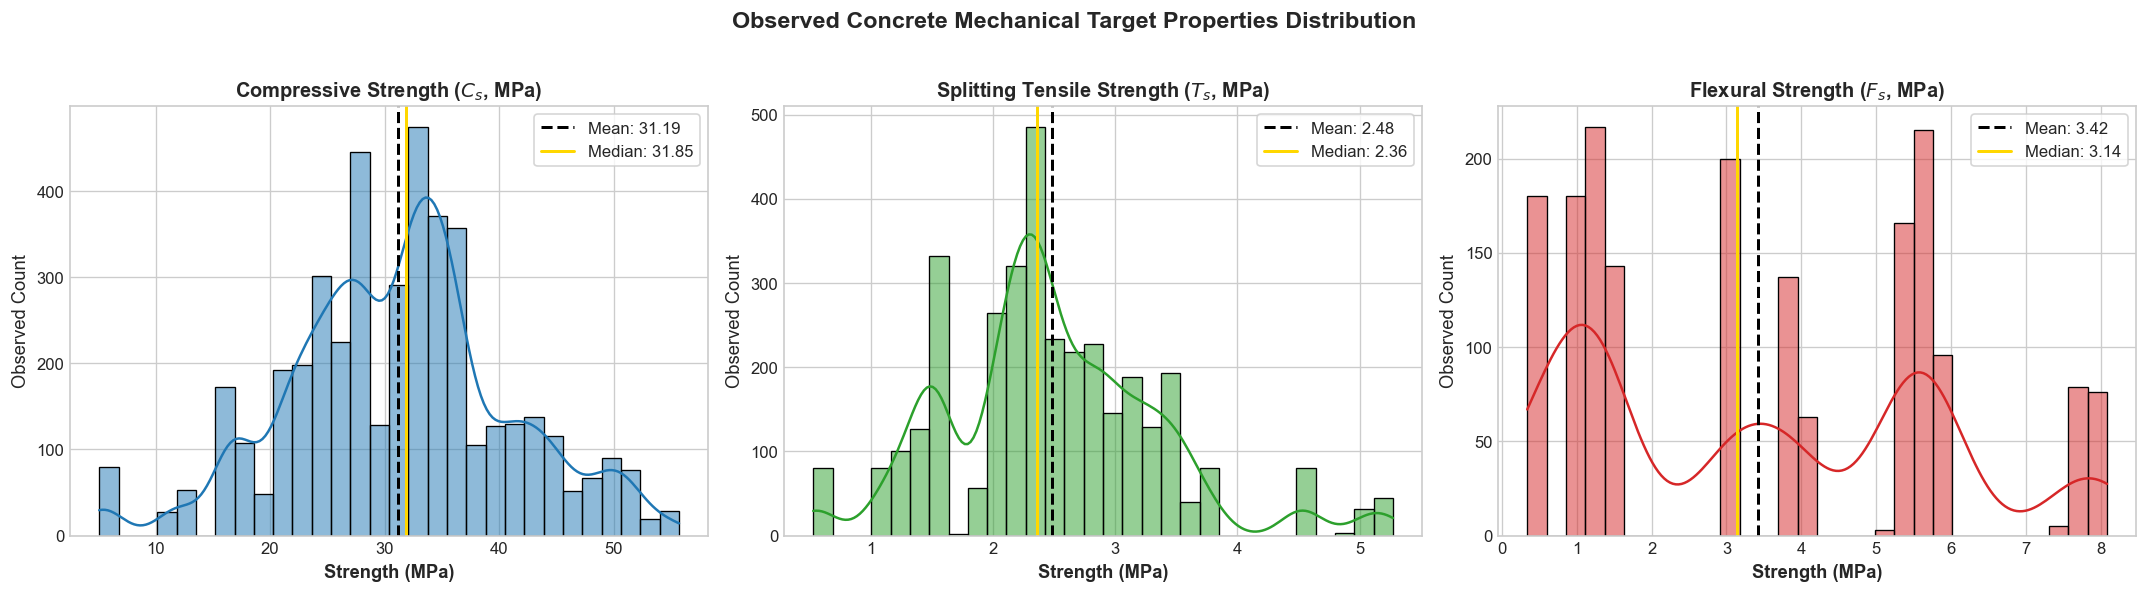

,Target,Observed N,Mean (MPa),Std (MPa),Min (MPa),Median (MPa),Max (MPa),IQR (MPa)
0,Cs_Mpa,4420,31.193,9.589,5.082,31.854,55.709,11.113
1,Ts_Mpa,3460,2.482,0.875,0.531,2.358,5.272,0.890
2,Fs_Mpa,1760,3.422,2.370,0.337,3.138,8.087,4.393


[SAVED] Target distributions saved to: c:\Users\jeetu\projects\Capstone\3rdYearsem5\figures\04_target_distributions.png


In [20]:
# 4. Target Variables Univariate Distribution (Observed Samples)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
colors = ["#1f77b4", "#2ca02c", "#d62728"]
titles = [
    "Compressive Strength ($C_s$, MPa)",
    "Splitting Tensile Strength ($T_s$, MPa)",
    "Flexural Strength ($F_s$, MPa)"
]

target_stats = []
for i, col in enumerate(TARGET_COLS):
    vals = df[col].dropna()
    sns.histplot(vals, kde=True, ax=axes[i], color=colors[i], bins=30, edgecolor="black", linewidth=0.8)
    axes[i].set_title(titles[i], fontweight="bold")
    axes[i].set_xlabel("Strength (MPa)", fontweight="bold")
    axes[i].set_ylabel("Observed Count")
    
    mean_val, median_val, std_val = vals.mean(), vals.median(), vals.std()
    axes[i].axvline(mean_val, color="black", linestyle="--", lw=1.8, label=f"Mean: {mean_val:.2f}")
    axes[i].axvline(median_val, color="gold", linestyle="-", lw=1.8, label=f"Median: {median_val:.2f}")
    axes[i].legend(loc="upper right", frameon=True)
    
    target_stats.append({
        "Target": col,
        "Observed N": len(vals),
        "Mean (MPa)": mean_val,
        "Std (MPa)": std_val,
        "Min (MPa)": vals.min(),
        "Median (MPa)": median_val,
        "Max (MPa)": vals.max(),
        "IQR (MPa)": vals.quantile(0.75) - vals.quantile(0.25)
    })

plt.suptitle("Observed Concrete Mechanical Target Properties Distribution", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "04_target_distributions.png")
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()

display(pd.DataFrame(target_stats).round(3))
print(f"[SAVED] Target distributions saved to: {fig_path}")


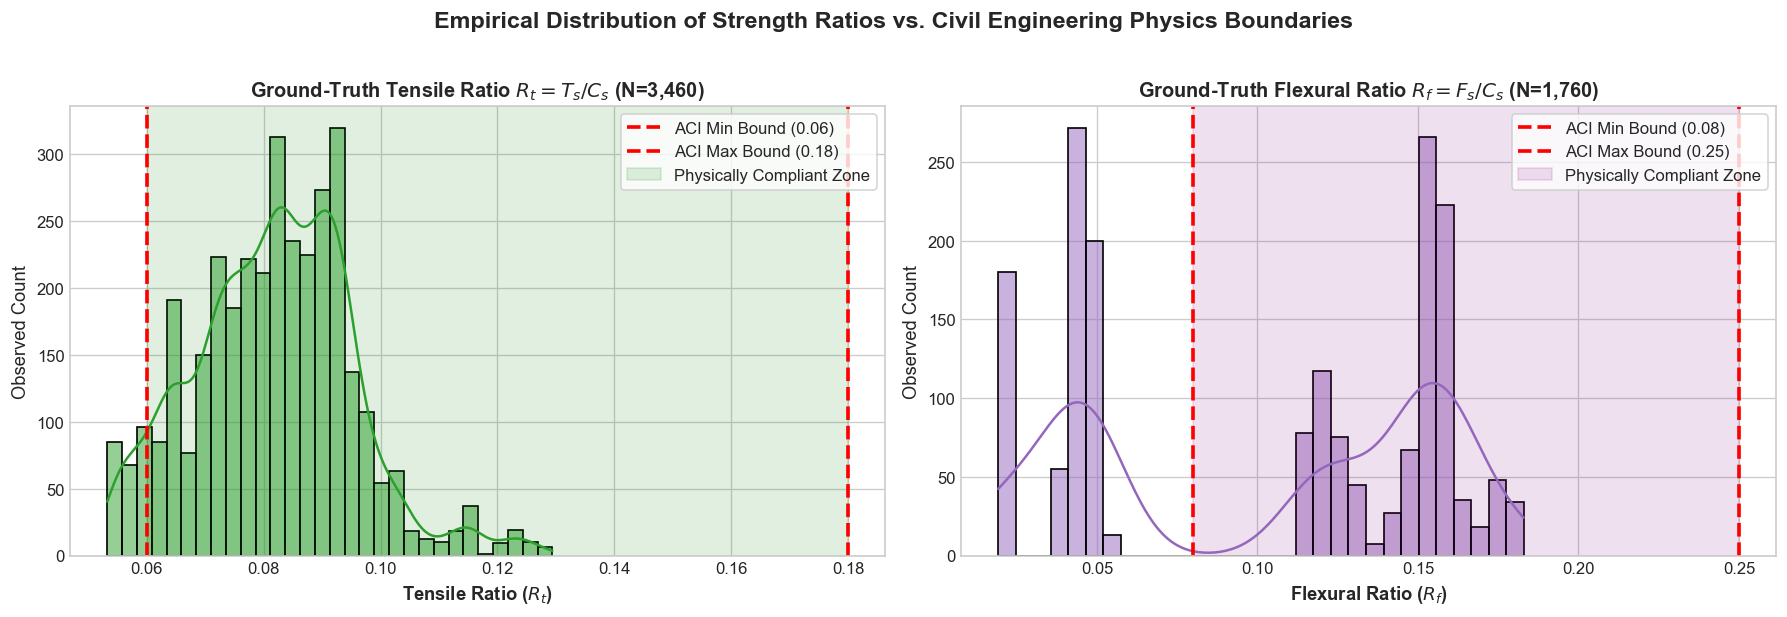

[SAVED] Ground truth mechanical ratios plot saved to: c:\Users\jeetu\projects\Capstone\3rdYearsem5\figures\05_ground_truth_mechanical_ratios.png
[AUDIT] Ground-Truth Tensile Ratio Compliance: 93.76% (6.24% outside ACI bounds)
[AUDIT] Ground-Truth Flexural Ratio Compliance: 59.09% (40.91% outside ACI bounds)


In [21]:
# 5. Ground Truth Mechanical Strength Ratios vs ACI 318 Design Code Bounds
# Tensile Ratio: Rt = Ts / Cs (ACI 318 expected bound: [0.06, 0.18])
# Flexural Ratio: Rf = Fs / Cs (ACI 318 expected bound: [0.08, 0.25])
df_clean = df.copy()
df_clean["Rt"] = df_clean["Ts_Mpa"] / df_clean["Cs_Mpa"]
df_clean["Rf"] = df_clean["Fs_Mpa"] / df_clean["Cs_Mpa"]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Tensile Ratio Plot
rt_valid = df_clean["Rt"].dropna()
sns.histplot(rt_valid, kde=True, ax=axes[0], color="#2ca02c", bins=30, edgecolor="black")
axes[0].axvline(0.06, color="red", linestyle="--", linewidth=2.2, label="ACI Min Bound (0.06)")
axes[0].axvline(0.18, color="red", linestyle="--", linewidth=2.2, label="ACI Max Bound (0.18)")
axes[0].axvspan(0.06, 0.18, color="green", alpha=0.12, label="Physically Compliant Zone")
axes[0].set_title(f"Ground-Truth Tensile Ratio $R_t = T_s / C_s$ (N={len(rt_valid):,})", fontweight="bold")
axes[0].set_xlabel("Tensile Ratio ($R_t$)", fontweight="bold")
axes[0].set_ylabel("Observed Count")
axes[0].legend(loc="upper right", frameon=True)

# Flexural Ratio Plot
rf_valid = df_clean["Rf"].dropna()
sns.histplot(rf_valid, kde=True, ax=axes[1], color="#9467bd", bins=30, edgecolor="black")
axes[1].axvline(0.08, color="red", linestyle="--", linewidth=2.2, label="ACI Min Bound (0.08)")
axes[1].axvline(0.25, color="red", linestyle="--", linewidth=2.2, label="ACI Max Bound (0.25)")
axes[1].axvspan(0.08, 0.25, color="purple", alpha=0.12, label="Physically Compliant Zone")
axes[1].set_title(f"Ground-Truth Flexural Ratio $R_f = F_s / C_s$ (N={len(rf_valid):,})", fontweight="bold")
axes[1].set_xlabel("Flexural Ratio ($R_f$)", fontweight="bold")
axes[1].set_ylabel("Observed Count")
axes[1].legend(loc="upper right", frameon=True)

plt.suptitle("Empirical Distribution of Strength Ratios vs. Civil Engineering Physics Boundaries", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "05_ground_truth_mechanical_ratios.png")
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()

# Calculate empirical ground truth compliance
rt_viol = np.mean((rt_valid < 0.06) | (rt_valid > 0.18)) * 100.0
rf_viol = np.mean((rf_valid < 0.08) | (rf_valid > 0.25)) * 100.0
print(f"[SAVED] Ground truth mechanical ratios plot saved to: {fig_path}")
print(f"[AUDIT] Ground-Truth Tensile Ratio Compliance: {100.0 - rt_viol:.2f}% ({rt_viol:.2f}% outside ACI bounds)")
print(f"[AUDIT] Ground-Truth Flexural Ratio Compliance: {100.0 - rf_viol:.2f}% ({rf_viol:.2f}% outside ACI bounds)")


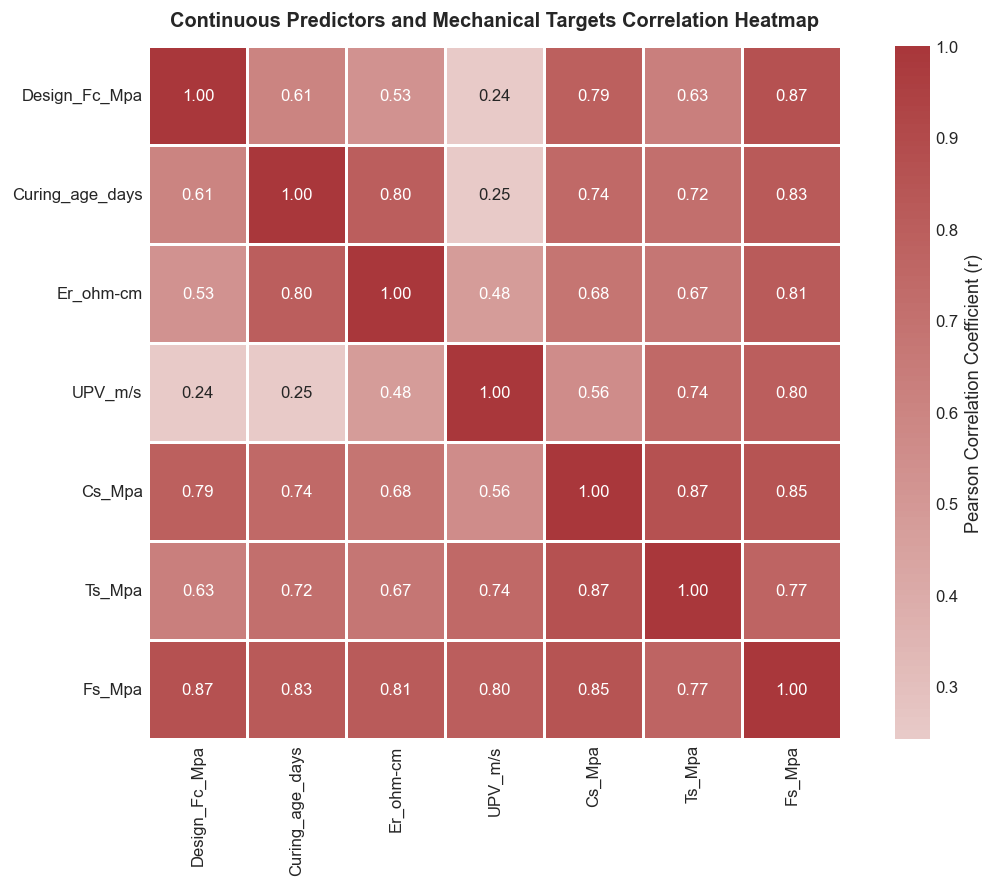

[SAVED] Correlation matrix heatmap saved to: c:\Users\jeetu\projects\Capstone\3rdYearsem5\figures\06_correlation_matrix.png


In [22]:
# 6. Pearson Correlation Matrix (Continuous Predictors + Mechanical Targets)
corr_cols = NUMERICAL_COLS + TARGET_COLS
corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(10, 7.5))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    square=True,
    linewidths=0.8,
    cbar_kws={"label": "Pearson Correlation Coefficient (r)"}
)
plt.title("Continuous Predictors and Mechanical Targets Correlation Heatmap", fontweight="bold", pad=12)
plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "06_correlation_matrix.png")
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"[SAVED] Correlation matrix heatmap saved to: {fig_path}")


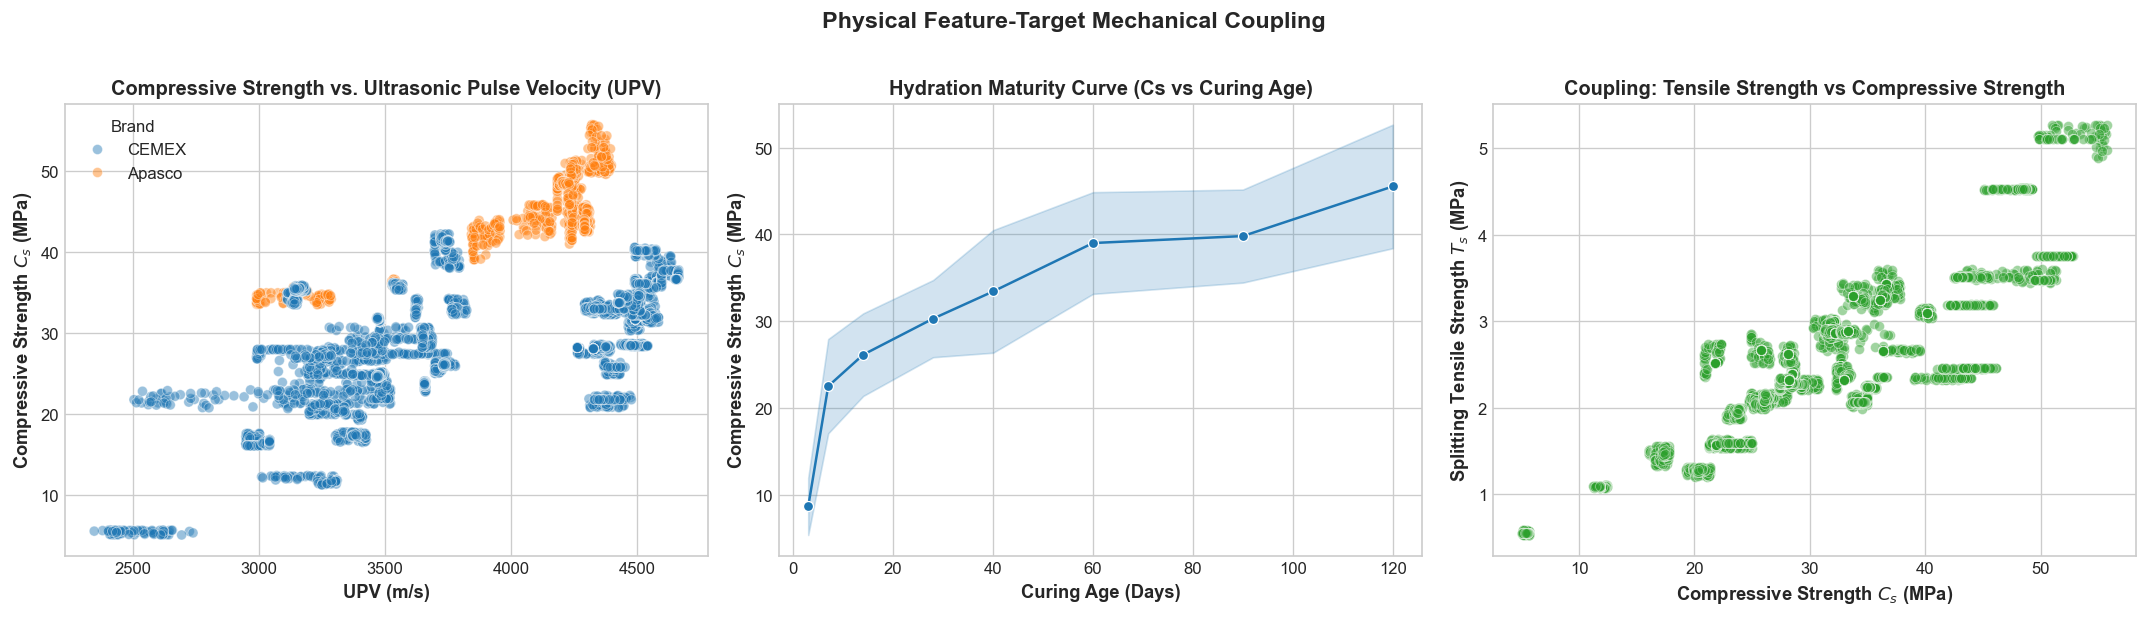

[SAVED] Feature-target relationship plots saved to: c:\Users\jeetu\projects\Capstone\3rdYearsem5\figures\07_feature_target_relationships.png


In [23]:
# 7. Bivariate Feature-Target Relationships
# Inspecting coupling between Non-Destructive Transit Velocity (UPV), Curing Maturity, and Mechanical Strengths
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Subplot A: UPV vs Compressive Strength
sns.scatterplot(data=df, x="UPV_m/s", y="Cs_Mpa", hue="Brand", alpha=0.45, ax=axes[0], palette="tab10")
axes[0].set_title("Compressive Strength vs. Ultrasonic Pulse Velocity (UPV)", fontweight="bold")
axes[0].set_xlabel("UPV (m/s)", fontweight="bold")
axes[0].set_ylabel("Compressive Strength $C_s$ (MPa)", fontweight="bold")

# Subplot B: Curing Age vs Compressive Strength
sns.lineplot(data=df, x="Curing_age_days", y="Cs_Mpa", ax=axes[1], color="#1f77b4", marker="o", errorbar="sd")
axes[1].set_title("Hydration Maturity Curve (Cs vs Curing Age)", fontweight="bold")
axes[1].set_xlabel("Curing Age (Days)", fontweight="bold")
axes[1].set_ylabel("Compressive Strength $C_s$ (MPa)", fontweight="bold")

# Subplot C: Compressive Strength vs Splitting Tensile Strength
sns.scatterplot(data=df.dropna(subset=["Cs_Mpa", "Ts_Mpa"]), x="Cs_Mpa", y="Ts_Mpa", alpha=0.45, ax=axes[2], color="#2ca02c")
axes[2].set_title("Coupling: Tensile Strength vs Compressive Strength", fontweight="bold")
axes[2].set_xlabel("Compressive Strength $C_s$ (MPa)", fontweight="bold")
axes[2].set_ylabel("Splitting Tensile Strength $T_s$ (MPa)", fontweight="bold")

plt.suptitle("Physical Feature-Target Mechanical Coupling", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "07_feature_target_relationships.png")
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"[SAVED] Feature-target relationship plots saved to: {fig_path}")


## 4. Leakage-Free Preprocessing Pipeline
To prevent information leakage from test specimens into the training pipeline:
1. **Train/Test Partitioning:** An 80/20 isolated partition ($N_{\text{train}}=3,536$, $N_{\text{test}}=884$) is generated before fitting transformers.
2. **Categorical Predictors:** One-Hot Encoded with `handle_unknown='ignore'`, expanding the 4 categorical variables into 15 binary indicator dimensions.
3. **Continuous Predictors:** Scaled using `RobustScaler` (median & IQR), ensuring extreme resistivity values do not dominate gradient updates.
4. **Target Properties & Masking:** Robust scalers for $C_s, T_s, F_s$ are fitted **strictly on observed training samples**. Missing entries receive a neutral matrix placeholder ($0.0$) and a binary observation mask ($m_{ij} = 0.0$) ensuring strictly zero error gradient during backpropagation.


In [24]:
# 1. Isolated Train/Test Split
train_df, test_df = train_test_split(df, test_size=0.2, random_state=SEED)
print(f"Dataset Partitioning: Train = {len(train_df):,} specimens (80%) | Test = {len(test_df):,} specimens (20%)")

# 2. Categorical One-Hot Encoding
ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
cat_train = ohe.fit_transform(train_df[CATEGORICAL_COLS])
cat_test = ohe.transform(test_df[CATEGORICAL_COLS])

# 3. Numerical Robust Scaling
scaler_x = RobustScaler()
num_train = scaler_x.fit_transform(train_df[NUMERICAL_COLS])
num_test = scaler_x.transform(test_df[NUMERICAL_COLS])

# 4. Concatenate Feature Matrices X
X_train = np.hstack([num_train, cat_train]).astype(np.float32)
X_test = np.hstack([num_test, cat_test]).astype(np.float32)
input_dim = X_train.shape[1]
print(f"Preprocessed Input Feature Vector Dimension: {input_dim} features")

# 5. Extract Raw Targets and Build Binary Observation Masks
y_train_raw = train_df[TARGET_COLS].to_numpy(dtype=np.float32)
y_test_raw = test_df[TARGET_COLS].to_numpy(dtype=np.float32)

mask_train = (~np.isnan(y_train_raw)).astype(np.float32)
mask_test = (~np.isnan(y_test_raw)).astype(np.float32)

# 6. Fit Target Scalers Strictly on Observed Training Samples
target_scalers = {}
target_centers = np.zeros(3, dtype=np.float32)
target_scales = np.ones(3, dtype=np.float32)
y_train_scaled = np.zeros_like(y_train_raw)
y_test_scaled = np.zeros_like(y_test_raw)

for i, col in enumerate(TARGET_COLS):
    sc = RobustScaler()
    observed_train = y_train_raw[mask_train[:, i] == 1.0, i].reshape(-1, 1)
    sc.fit(observed_train)
    target_scalers[col] = sc
    target_centers[i] = sc.center_[0]
    target_scales[i] = sc.scale_[0]
    
    # Scale observed samples; unobserved remain 0.0 placeholder
    tr_obs_idx = mask_train[:, i] == 1.0
    y_train_scaled[tr_obs_idx, i] = sc.transform(y_train_raw[tr_obs_idx, i].reshape(-1, 1)).ravel()
    
    te_obs_idx = mask_test[:, i] == 1.0
    y_test_scaled[te_obs_idx, i] = sc.transform(y_test_raw[te_obs_idx, i].reshape(-1, 1)).ravel()

preprocessor = {
    "ohe": ohe,
    "scaler_x": scaler_x,
    "target_scalers": target_scalers,
    "target_centers": target_centers,
    "target_scales": target_scales,
    "input_dim": input_dim,
    "categorical_cols": CATEGORICAL_COLS,
    "numerical_cols": NUMERICAL_COLS,
    "target_cols": TARGET_COLS,
    "n_train": len(train_df),
    "n_test": len(test_df),
}

print(f"Fitted Target Centers (Medians MPa) : {target_centers}")
print(f"Fitted Target Scales  (IQRs MPa)    : {target_scales}")


Dataset Partitioning: Train = 3,536 specimens (80%) | Test = 884 specimens (20%)
Preprocessed Input Feature Vector Dimension: 19 features
Fitted Target Centers (Medians MPa) : [31.8438     2.3713999  3.1381   ]
Fitted Target Scales  (IQRs MPa)    : [11.085499   0.8661248  4.3878   ]


## 5. Model Architecture & Physics-Informed Multi-Task Loss Setup
We instantiate the deep multi-task network (`PIM_MTL_Net`) and the differentiable physics-informed loss (`PIM_MTL_Loss`).

### Mathematical Formulation
$$\mathcal{L}_{total} = \mathcal{L}_{data} + \lambda_{phys} \mathcal{L}_{phys}$$

1. **Masked Empirical Data Loss (Gradient Gating):**
$$\mathcal{L}_{data} = \sum_{j \in \{Cs, Ts, Fs\}} w_j \left[ \frac{\sum_{i=1}^N m_{ij} (y_{ij} - \hat{y}_{ij})^2}{\max\left(1, \sum_{i=1}^N m_{ij}\right)} \right]$$
*When target $j$ is missing ($m_{ij} = 0$), the error gradient is strictly zero: $\frac{\partial \mathcal{L}_{data}}{\partial \hat{y}_{ij}} \equiv 0$.*

2. **Differentiable Physics Ratio Regularization (Unmasked on All Samples):**
$$R_t = \frac{\hat{T}_s}{\hat{C}_s + \epsilon}, \quad R_f = \frac{\hat{F}_s}{\hat{C}_s + \epsilon}$$
$$\mathcal{L}_{phys} = \frac{1}{N} \sum_{i=1}^N \Big[ \text{ReLU}(R_{t,i} - 0.18)^2 + \text{ReLU}(0.06 - R_{t,i})^2 + \text{ReLU}(R_{f,i} - 0.25)^2 + \text{ReLU}(0.08 - R_{f,i})^2 \Big]$$


In [25]:
# Instantiate Model
model = PIM_MTL_Net(
    input_dim=input_dim,
    hidden_dims=[128, 64, 32],
    dropout=0.2,
    use_batch_norm=True
).to(device)

# Instantiate Physics-Informed Multi-Task Loss
criterion = PIM_MTL_Loss(
    task_weights={"Cs": 1.0, "Ts": 1.2, "Fs": 1.5},
    lambda_phys=0.5,
    rt_bounds=(0.06, 0.18),
    rf_bounds=(0.08, 0.25),
    target_centers=preprocessor["target_centers"],
    target_scales=preprocessor["target_scales"],
    normalization="per_task"
).to(device)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("--- PIM_MTL_Net Architecture Summary ---")
print(model)
print(f"\nTotal Trainable Parameters: {total_params:,} parameters")


--- PIM_MTL_Net Architecture Summary ---
PIM_MTL_Net(
  (fc1): Linear(in_features=19, out_features=128, bias=True)
  (bn1): SafeBatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (act1): GELU(approximate='none')
  (drop1): Dropout(p=0.2, inplace=False)
  (fc2): Linear(in_features=128, out_features=64, bias=True)
  (bn2): SafeBatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (act2): GELU(approximate='none')
  (fc3): Linear(in_features=64, out_features=32, bias=True)
  (head_cs): Linear(in_features=32, out_features=1, bias=True)
  (head_ts): Linear(in_features=32, out_features=1, bias=True)
  (head_fs): Linear(in_features=32, out_features=1, bias=True)
)

Total Trainable Parameters: 13,379 parameters


## 6. Model Training Loop (60 Epochs)
We configure the batch data loaders, Adam optimizer, and Cosine Annealing learning rate scheduler.
- **Batch Size:** 64
- **Epochs:** 60
- **Base Learning Rate:** $1 \times 10^{-3}$ (decaying to $1 \times 10^{-5}$)
- **Weight Decay ($L_2$):** $1 \times 10^{-4}$
- **Gradient Norm Clipping:** `max_norm = 5.0`
- **Validation Evaluation:** Evaluated on held-out test split at every epoch to track empirical loss and physics compliance simultaneously.


In [26]:
BATCH_SIZE = 64
EPOCHS = 60
LR = 1e-3

# PyTorch DataLoaders
train_dataset = TensorDataset(
    torch.tensor(X_train, dtype=torch.float32),
    torch.tensor(y_train_scaled, dtype=torch.float32),
    torch.tensor(mask_train, dtype=torch.float32)
)
test_dataset = TensorDataset(
    torch.tensor(X_test, dtype=torch.float32),
    torch.tensor(y_test_scaled, dtype=torch.float32),
    torch.tensor(mask_test, dtype=torch.float32)
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-5)

history = {
    "epoch": [],
    "train_total": [], "train_data": [], "train_phys": [],
    "val_total": [], "val_data": [], "val_phys": [],
    "lr": []
}

print(f"Starting PIM-MTL Training on {device} (Epochs: {EPOCHS}, Batch Size: {BATCH_SIZE}, LR: {LR})...\n")
print(f"{'Epoch':<8} | {'Train Total':<12} | {'Train Data':<12} | {'Train Phys':<12} | {'Val Total':<12} | {'Val Data':<12} | {'Val Phys':<12}")
print("-" * 92)

for epoch in range(1, EPOCHS + 1):
    # Training Step
    model.train()
    tr_total, tr_data, tr_phys = 0.0, 0.0, 0.0
    for bx, by, bm in train_loader:
        bx, by, bm = bx.to(device), by.to(device), bm.to(device)
        optimizer.zero_grad()
        preds = model(bx)
        loss, l_data, l_phys = criterion(preds, by, bm)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()
        
        tr_total += loss.item() * len(bx)
        tr_data += l_data.item() * len(bx)
        tr_phys += l_phys.item() * len(bx)
        
    scheduler.step()
    n_tr = len(X_train)
    tr_total /= n_tr
    tr_data /= n_tr
    tr_phys /= n_tr
    
    # Validation Step
    model.eval()
    val_total, val_data, val_phys = 0.0, 0.0, 0.0
    with torch.no_grad():
        for bx, by, bm in test_loader:
            bx, by, bm = bx.to(device), by.to(device), bm.to(device)
            preds = model(bx)
            v_loss, v_data, v_phys = criterion(preds, by, bm)
            val_total += v_loss.item() * len(bx)
            val_data += v_data.item() * len(bx)
            val_phys += v_phys.item() * len(bx)
            
    n_te = len(X_test)
    val_total /= n_te
    val_data /= n_te
    val_phys /= n_te
    
    current_lr = scheduler.get_last_lr()[0]
    history["epoch"].append(epoch)
    history["train_total"].append(tr_total)
    history["train_data"].append(tr_data)
    history["train_phys"].append(tr_phys)
    history["val_total"].append(val_total)
    history["val_data"].append(val_data)
    history["val_phys"].append(val_phys)
    history["lr"].append(current_lr)
    
    if epoch % 10 == 0 or epoch == 1 or epoch == EPOCHS:
        print(f"Ep {epoch:03d}/{EPOCHS:03d} | {tr_total:<12.4f} | {tr_data:<12.4f} | {tr_phys:<12.6f} | {val_total:<12.4f} | {val_data:<12.4f} | {val_phys:<12.6f}")

print("-" * 92)
print("Training Completed Successfully!")


Starting PIM-MTL Training on cuda (Epochs: 60, Batch Size: 64, LR: 0.001)...

Epoch    | Train Total  | Train Data   | Train Phys   | Val Total    | Val Data     | Val Phys    
--------------------------------------------------------------------------------------------
Ep 001/060 | 1.6800       | 1.6739       | 0.012079     | 0.1165       | 0.1161       | 0.000703    
Ep 010/060 | 0.1325       | 0.1324       | 0.000304     | 0.0581       | 0.0580       | 0.000148    
Ep 020/060 | 0.1091       | 0.1089       | 0.000427     | 0.0486       | 0.0484       | 0.000375    
Ep 030/060 | 0.0857       | 0.0855       | 0.000319     | 0.0378       | 0.0377       | 0.000300    
Ep 040/060 | 0.0841       | 0.0840       | 0.000317     | 0.0368       | 0.0366       | 0.000372    
Ep 050/060 | 0.0780       | 0.0779       | 0.000371     | 0.0340       | 0.0339       | 0.000366    
Ep 060/060 | 0.0741       | 0.0739       | 0.000352     | 0.0347       | 0.0345       | 0.000338    
-----------------------

## 7. Model Checkpoint & Preprocessor Persistence
We serialize the trained PyTorch model architecture and weights to `models/pim_mtl_model.pt` and the preprocessing pipeline metadata to `models/preprocessor.joblib`. We then execute a test reload to verify flawless offline inference.


In [27]:
model_save_path = os.path.join(MODELS_DIR, "pim_mtl_model.pt")
preproc_save_path = os.path.join(MODELS_DIR, "preprocessor.joblib")

# Save PyTorch Model Checkpoint
model.save(model_save_path, extra={"epochs": EPOCHS, "seed": SEED, "input_dim": input_dim})
print(f"[SAVED] Trained PIM-MTL PyTorch Model saved to : {model_save_path}")

# Save Preprocessor Metadata
joblib.dump(preprocessor, preproc_save_path)
print(f"[SAVED] Fitted Preprocessing Pipeline saved to : {preproc_save_path}")

# Verification: Reload and Perform Inference on 5 Sample Specimens
print("\n--- Inference Verification from Saved Artifacts ---")
reloaded_model = PIM_MTL_Net.load(model_save_path, map_location="cpu")
reloaded_model.eval()
reloaded_preproc = joblib.load(preproc_save_path)

sample_x = torch.tensor(X_test[:5], dtype=torch.float32)
with torch.no_grad():
    sample_preds_scaled = reloaded_model(sample_x).numpy()

sample_preds_mpa = sample_preds_scaled * reloaded_preproc["target_scales"] + reloaded_preproc["target_centers"]
demo_df = pd.DataFrame(sample_preds_mpa, columns=["Pred_Cs_Mpa", "Pred_Ts_Mpa", "Pred_Fs_Mpa"])
demo_df["Pred_Rt"] = demo_df["Pred_Ts_Mpa"] / demo_df["Pred_Cs_Mpa"]
demo_df["Pred_Rf"] = demo_df["Pred_Fs_Mpa"] / demo_df["Pred_Cs_Mpa"]

print("Sample Predictions on First 5 Unseen Test Specimens:")
display(demo_df.round(3))


[SAVED] Trained PIM-MTL PyTorch Model saved to : c:\Users\jeetu\projects\Capstone\3rdYearsem5\models\pim_mtl_model.pt
[SAVED] Fitted Preprocessing Pipeline saved to : c:\Users\jeetu\projects\Capstone\3rdYearsem5\models\preprocessor.joblib

--- Inference Verification from Saved Artifacts ---
Sample Predictions on First 5 Unseen Test Specimens:


,Pred_Cs_Mpa,Pred_Ts_Mpa,Pred_Fs_Mpa,Pred_Rt,Pred_Rf
0,19.490000,1.366,3.047,0.070,0.156
1,25.507000,2.110,3.886,0.083,0.152
2,41.804001,2.285,4.721,0.055,0.113
3,41.705002,2.289,4.673,0.055,0.112
4,31.292999,2.671,3.108,0.085,0.099


## 8. Comprehensive Diagnostic & Comparison Plots (In Proper Order)
In this section, we generate and display the complete suite of diagnostic and comparative visualizations in proper sequential order, saving all figures to `figures/`:
1. **Plot 1: Training Convergence Curves (3 Panels):** Total joint loss, masked empirical MSE, and differentiable physics ratio penalty.
2. **Plot 2: Parity Plots (Predicted vs Actual):** Independent scatter plots for $C_s, T_s, F_s$ along the 1:1 identity line, annotated with $R^2$ and RMSE.
3. **Plot 3: Residual Error Distributions:** Zero-centered error distributions ($y_{\text{pred}} - y_{\text{true}}$) evaluating homoscedasticity and absence of systematic bias.
4. **Plot 4: Ground Truth vs. Predicted Mechanical Ratio Comparisons:** Distribution of $R_t$ and $R_f$ relative to ACI 318 upper and lower design boundaries.
5. **Plot 5: Multi-Metric Target Performance & Relative Error Profile:** Bar chart comparison of $R^2$, RMSE, MAE, and normalized relative error percentages (% of observed mean) across tasks.
6. **Plot 6: Physical Feasibility & Code Compliance Audit:** Quantifying compliance for tensile ratios, flexural ratios, and physically impossible predictions ($T_s \ge C_s$).


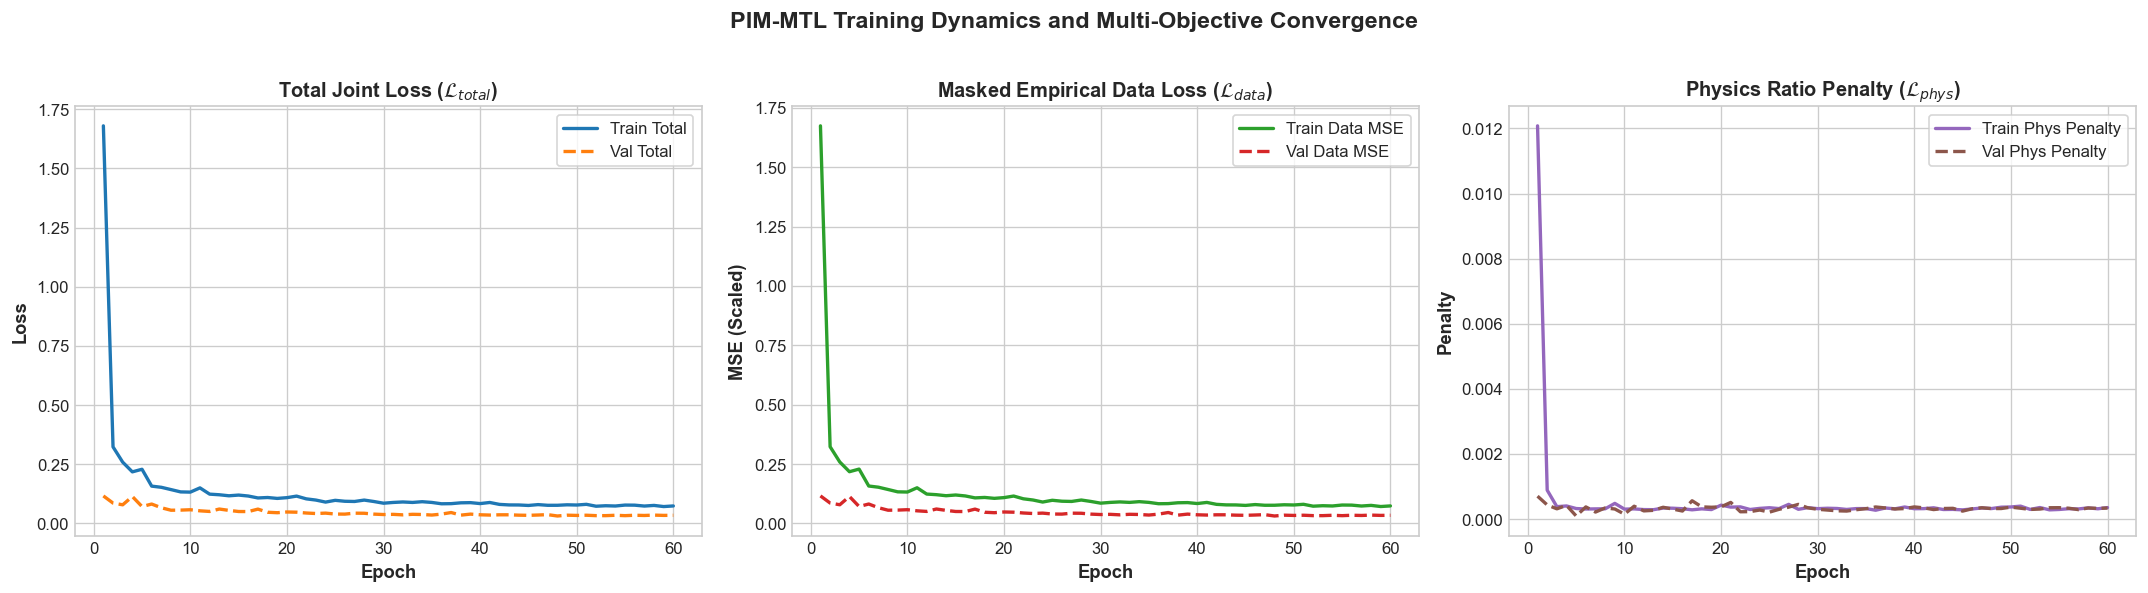

[SAVED] Convergence curves saved to: c:\Users\jeetu\projects\Capstone\3rdYearsem5\figures\08_training_convergence_curves.png


In [28]:
# Plot 1: Training & Validation Convergence Curves
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

# Subplot 1: Total Joint Loss
axes[0].plot(history["epoch"], history["train_total"], label="Train Total", color="#1f77b4", lw=2)
axes[0].plot(history["epoch"], history["val_total"], label="Val Total", color="#ff7f0e", lw=2, linestyle="--")
axes[0].set_title(r"Total Joint Loss ($\mathcal{L}_{total}$)", fontweight="bold")
axes[0].set_xlabel("Epoch", fontweight="bold")
axes[0].set_ylabel("Loss", fontweight="bold")
axes[0].legend(loc="upper right", frameon=True)

# Subplot 2: Masked Empirical Data Loss
axes[1].plot(history["epoch"], history["train_data"], label="Train Data MSE", color="#2ca02c", lw=2)
axes[1].plot(history["epoch"], history["val_data"], label="Val Data MSE", color="#d62728", lw=2, linestyle="--")
axes[1].set_title(r"Masked Empirical Data Loss ($\mathcal{L}_{data}$)", fontweight="bold")
axes[1].set_xlabel("Epoch", fontweight="bold")
axes[1].set_ylabel("MSE (Scaled)", fontweight="bold")
axes[1].legend(loc="upper right", frameon=True)

# Subplot 3: Physics Ratio Penalty
axes[2].plot(history["epoch"], history["train_phys"], label="Train Phys Penalty", color="#9467bd", lw=2)
axes[2].plot(history["epoch"], history["val_phys"], label="Val Phys Penalty", color="#8c564b", lw=2, linestyle="--")
axes[2].set_title(r"Physics Ratio Penalty ($\mathcal{L}_{phys}$)", fontweight="bold")
axes[2].set_xlabel("Epoch", fontweight="bold")
axes[2].set_ylabel("Penalty", fontweight="bold")
axes[2].legend(loc="upper right", frameon=True)

plt.suptitle("PIM-MTL Training Dynamics and Multi-Objective Convergence", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "08_training_convergence_curves.png")
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"[SAVED] Convergence curves saved to: {fig_path}")


In [29]:
# Generate Model Predictions on Unseen Test Split
model.eval()
with torch.no_grad():
    test_preds_scaled = model(torch.tensor(X_test, dtype=torch.float32).to(device)).cpu().numpy()

# Denormalize predictions back to physical MPa units
test_preds_raw = test_preds_scaled * preprocessor["target_scales"] + preprocessor["target_centers"]
print(f"Generated predictions for {len(test_preds_raw):,} test specimens.")


Generated predictions for 884 test specimens.


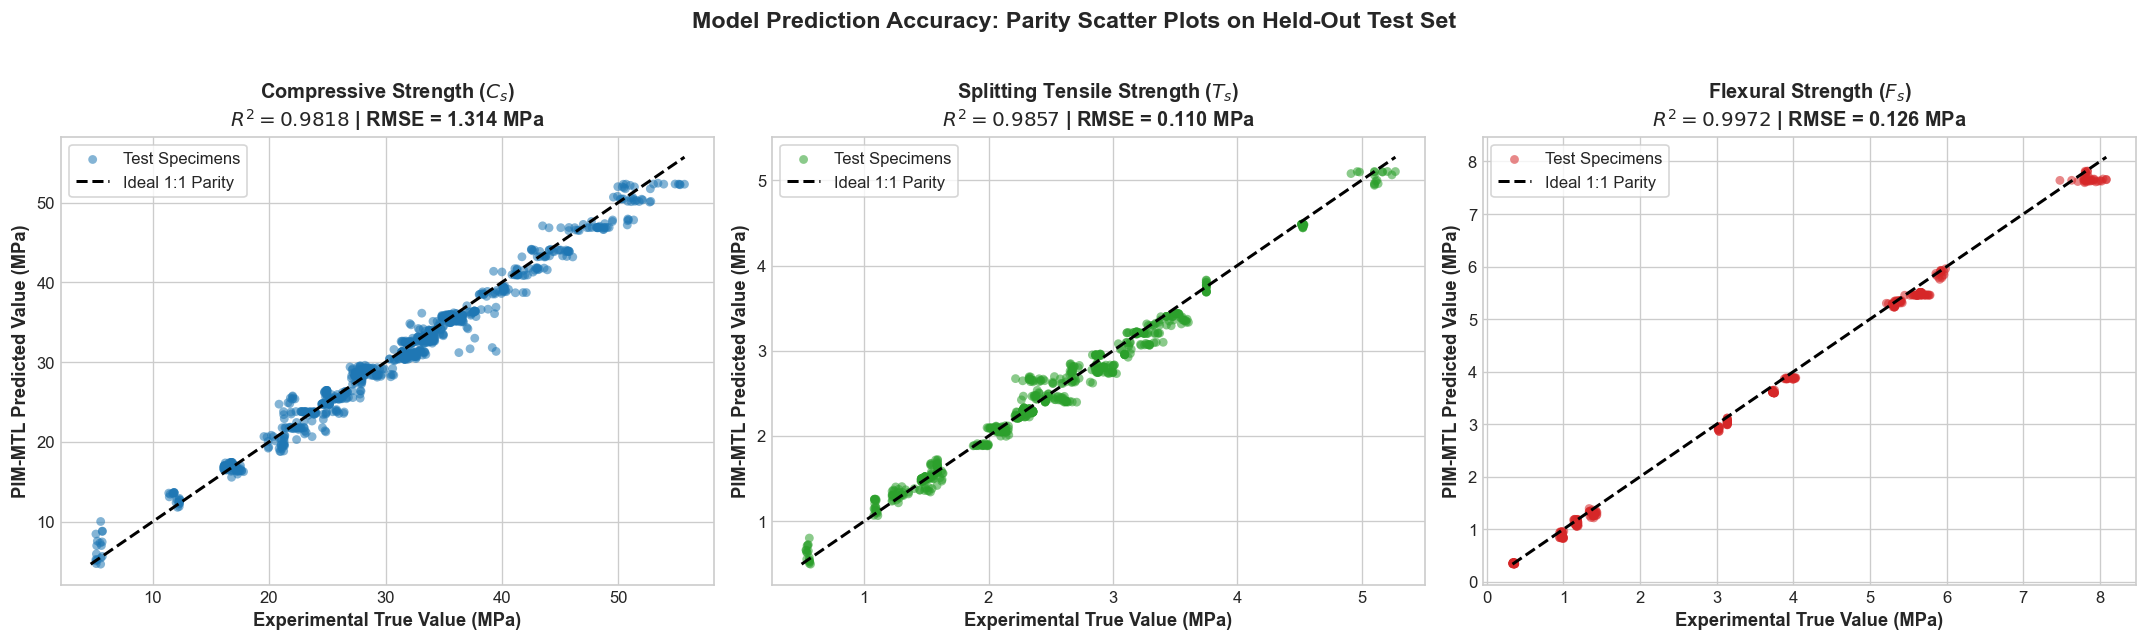

[SAVED] Parity plots saved to: c:\Users\jeetu\projects\Capstone\3rdYearsem5\figures\09_parity_plots_pred_vs_actual.png


In [30]:
# Plot 2: Parity Plots (Predicted vs Actual)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
colors = ["#1f77b4", "#2ca02c", "#d62728"]
titles = [
    "Compressive Strength ($C_s$)",
    "Splitting Tensile Strength ($T_s$)",
    "Flexural Strength ($F_s$)"
]

target_metrics = {}
for i, col in enumerate(TARGET_COLS):
    valid_idx = mask_test[:, i] == 1.0
    y_true = y_test_raw[valid_idx, i]
    y_pred = test_preds_raw[valid_idx, i]
    
    r2 = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    target_metrics[col] = {"r2": r2, "rmse": rmse, "mae": mae, "n": int(valid_idx.sum())}
    
    # Scatter plot
    axes[i].scatter(y_true, y_pred, alpha=0.55, color=colors[i], edgecolors="none", s=28, label="Test Specimens")
    min_val = min(y_true.min(), y_pred.min())
    max_val = max(y_true.max(), y_pred.max())
    axes[i].plot([min_val, max_val], [min_val, max_val], "k--", lw=1.8, label="Ideal 1:1 Parity")
    
    axes[i].set_title(f"{titles[i]}\n$R^2 = {r2:.4f}$ | RMSE = {rmse:.3f} MPa", fontweight="bold")
    axes[i].set_xlabel("Experimental True Value (MPa)", fontweight="bold")
    axes[i].set_ylabel("PIM-MTL Predicted Value (MPa)", fontweight="bold")
    axes[i].legend(loc="upper left", frameon=True)

plt.suptitle("Model Prediction Accuracy: Parity Scatter Plots on Held-Out Test Set", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "09_parity_plots_pred_vs_actual.png")
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"[SAVED] Parity plots saved to: {fig_path}")


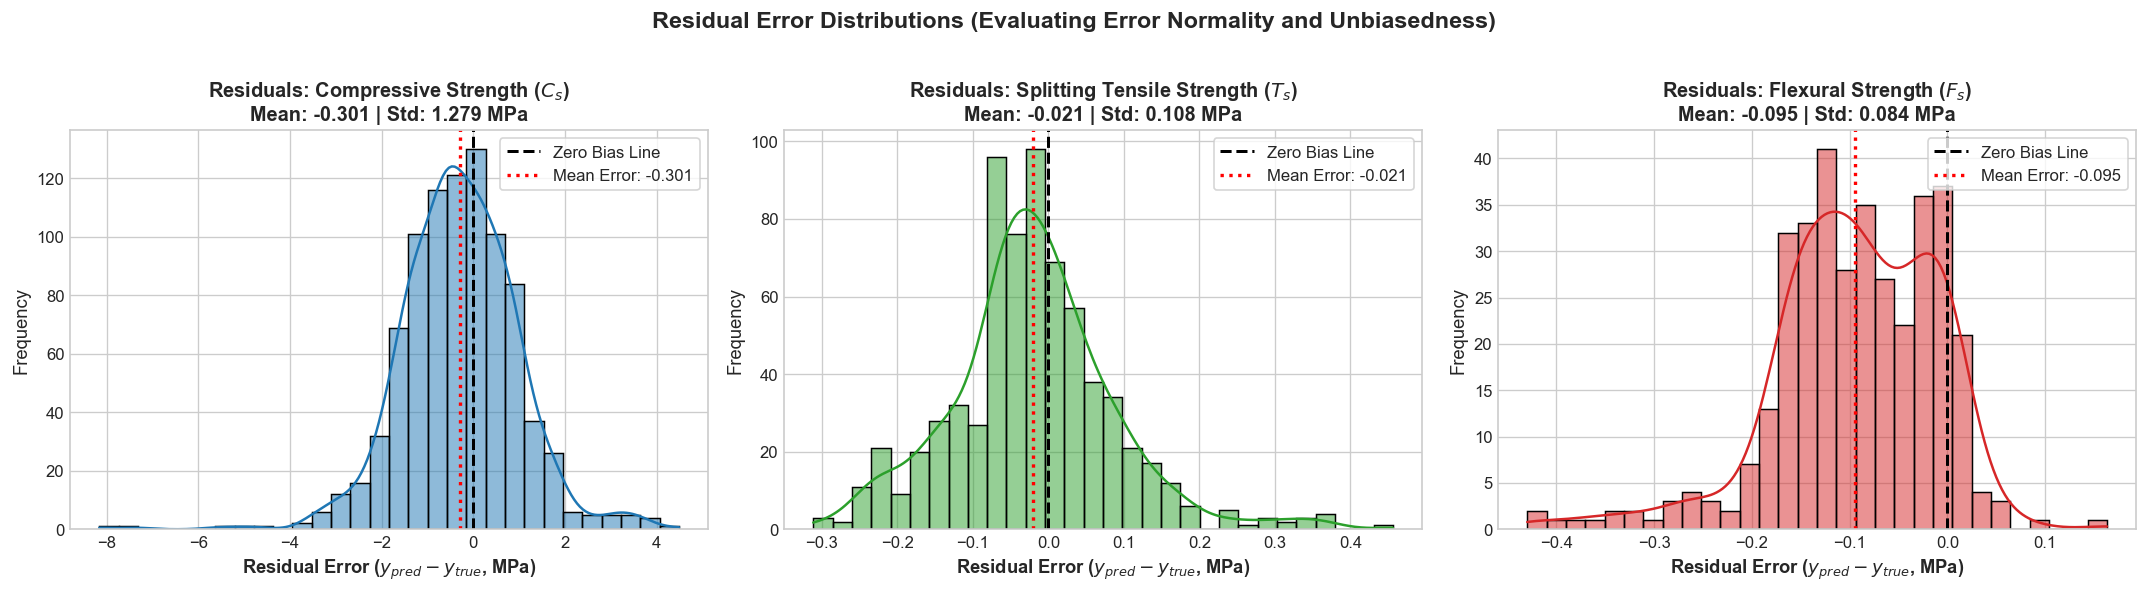

[SAVED] Residual distributions saved to: c:\Users\jeetu\projects\Capstone\3rdYearsem5\figures\10_residual_error_distributions.png


In [31]:
# Plot 3: Residual Error Distributions
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

for i, col in enumerate(TARGET_COLS):
    valid_idx = mask_test[:, i] == 1.0
    residuals = test_preds_raw[valid_idx, i] - y_test_raw[valid_idx, i]
    
    sns.histplot(residuals, kde=True, ax=axes[i], color=colors[i], bins=30, edgecolor="black")
    axes[i].axvline(0, color="black", linestyle="--", lw=1.8, label="Zero Bias Line")
    axes[i].axvline(residuals.mean(), color="red", linestyle=":", lw=2.0, label=f"Mean Error: {residuals.mean():.3f}")
    
    axes[i].set_title(f"Residuals: {titles[i]}\nMean: {residuals.mean():.3f} | Std: {residuals.std():.3f} MPa", fontweight="bold")
    axes[i].set_xlabel("Residual Error ($y_{pred} - y_{true}$, MPa)", fontweight="bold")
    axes[i].set_ylabel("Frequency")
    axes[i].legend(loc="upper right", frameon=True)

plt.suptitle("Residual Error Distributions (Evaluating Error Normality and Unbiasedness)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "10_residual_error_distributions.png")
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"[SAVED] Residual distributions saved to: {fig_path}")


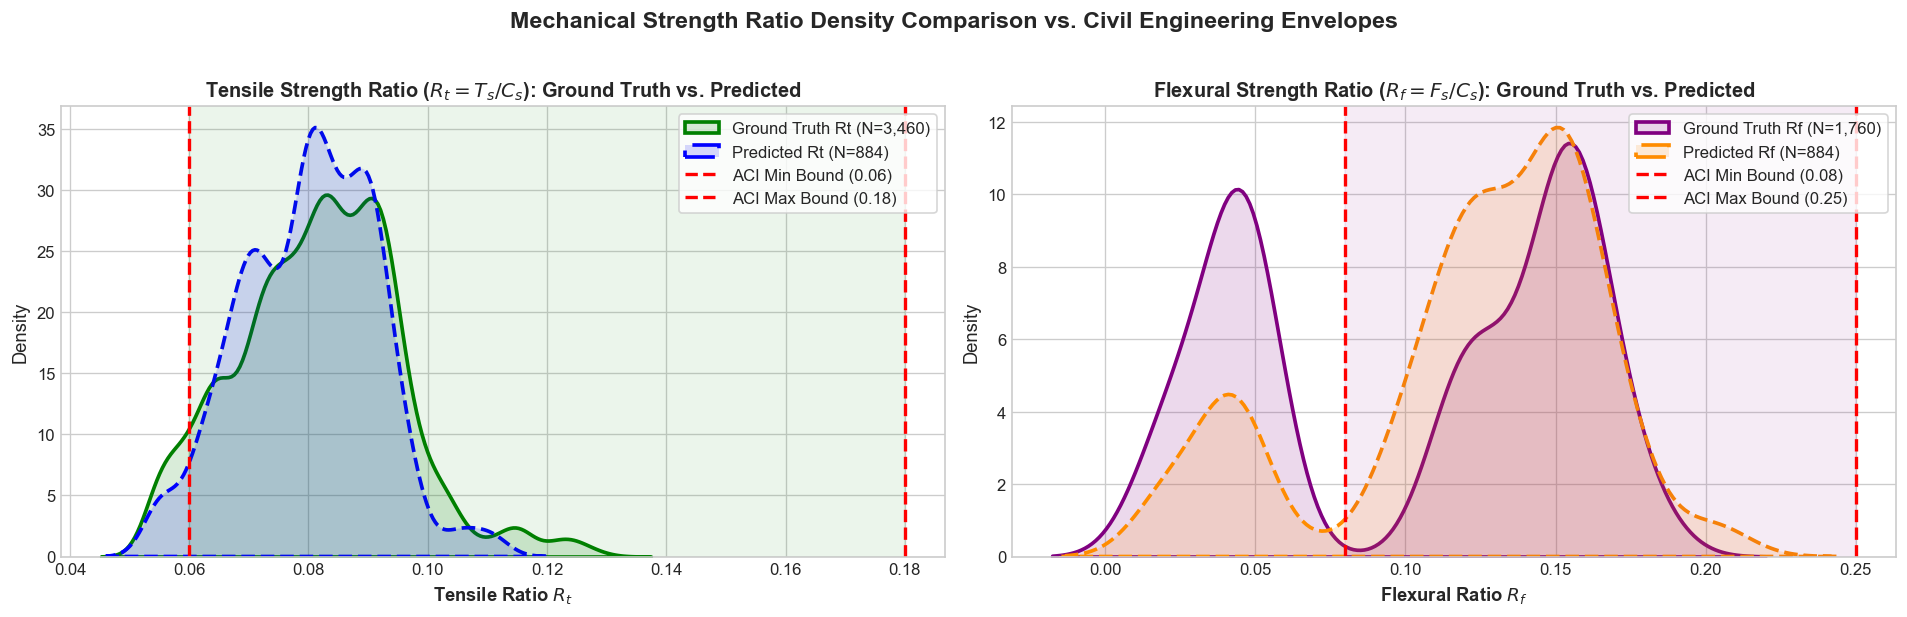

[SAVED] Ratio comparison plot saved to: c:\Users\jeetu\projects\Capstone\3rdYearsem5\figures\11_ratio_comparison_gt_vs_pred.png


In [32]:
# Plot 4: Mechanical Ratio Comparison (Ground Truth vs Predicted)
cs_pred_safe = np.maximum(test_preds_raw[:, 0], 1.0)
ts_pred_safe = test_preds_raw[:, 1]
fs_pred_safe = test_preds_raw[:, 2]

pred_rt = ts_pred_safe / cs_pred_safe
pred_rf = fs_pred_safe / cs_pred_safe

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Subplot 4A: Tensile Ratio Comparison
sns.kdeplot(rt_valid, ax=axes[0], color="green", lw=2.2, label=f"Ground Truth Rt (N={len(rt_valid):,})", fill=True, alpha=0.15)
sns.kdeplot(pred_rt, ax=axes[0], color="blue", lw=2.2, linestyle="--", label=f"Predicted Rt (N={len(pred_rt):,})", fill=True, alpha=0.15)
axes[0].axvline(0.06, color="red", linestyle="--", lw=2, label="ACI Min Bound (0.06)")
axes[0].axvline(0.18, color="red", linestyle="--", lw=2, label="ACI Max Bound (0.18)")
axes[0].axvspan(0.06, 0.18, color="green", alpha=0.08)
axes[0].set_title("Tensile Strength Ratio ($R_t = T_s / C_s$): Ground Truth vs. Predicted", fontweight="bold")
axes[0].set_xlabel("Tensile Ratio $R_t$", fontweight="bold")
axes[0].legend(loc="upper right", frameon=True)

# Subplot 4B: Flexural Ratio Comparison
sns.kdeplot(rf_valid, ax=axes[1], color="purple", lw=2.2, label=f"Ground Truth Rf (N={len(rf_valid):,})", fill=True, alpha=0.15)
sns.kdeplot(pred_rf, ax=axes[1], color="darkorange", lw=2.2, linestyle="--", label=f"Predicted Rf (N={len(pred_rf):,})", fill=True, alpha=0.15)
axes[1].axvline(0.08, color="red", linestyle="--", lw=2, label="ACI Min Bound (0.08)")
axes[1].axvline(0.25, color="red", linestyle="--", lw=2, label="ACI Max Bound (0.25)")
axes[1].axvspan(0.08, 0.25, color="purple", alpha=0.08)
axes[1].set_title("Flexural Strength Ratio ($R_f = F_s / C_s$): Ground Truth vs. Predicted", fontweight="bold")
axes[1].set_xlabel("Flexural Ratio $R_f$", fontweight="bold")
axes[1].legend(loc="upper right", frameon=True)

plt.suptitle("Mechanical Strength Ratio Density Comparison vs. Civil Engineering Envelopes", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "11_ratio_comparison_gt_vs_pred.png")
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"[SAVED] Ratio comparison plot saved to: {fig_path}")


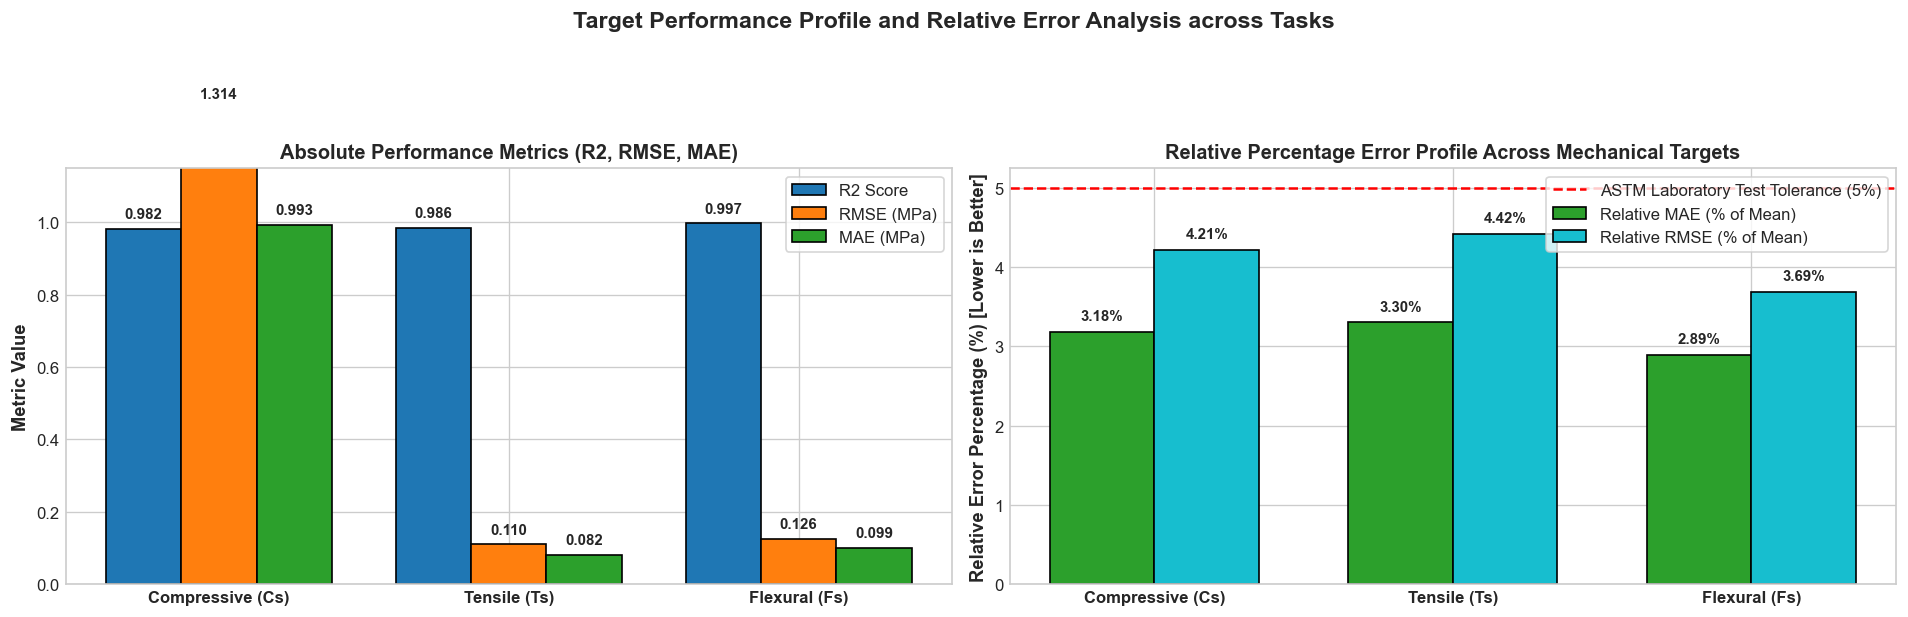

[SAVED] Target performance comparison plot saved to: c:\Users\jeetu\projects\Capstone\3rdYearsem5\figures\12_model_performance_comparison.png


In [33]:
# Plot 5: Multi-Metric Target Performance & Relative Error Profile
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Subplot 5A: Absolute Metrics Across Tasks for PIM-MTL
targets = ["Cs_Mpa", "Ts_Mpa", "Fs_Mpa"]
target_names = ["Compressive (Cs)", "Tensile (Ts)", "Flexural (Fs)"]
r2_vals = [target_metrics[c]["r2"] for c in targets]
rmse_vals = [target_metrics[c]["rmse"] for c in targets]
mae_vals = [target_metrics[c]["mae"] for c in targets]
x = np.arange(len(targets))
w = 0.26

axes[0].bar(x - w, r2_vals, width=w, label="R2 Score", color="#1f77b4", edgecolor="black")
axes[0].bar(x, rmse_vals, width=w, label="RMSE (MPa)", color="#ff7f0e", edgecolor="black")
axes[0].bar(x + w, mae_vals, width=w, label="MAE (MPa)", color="#2ca02c", edgecolor="black")
axes[0].set_xticks(x)
axes[0].set_xticklabels(target_names, fontweight="bold")
axes[0].set_ylabel("Metric Value", fontweight="bold")
axes[0].set_title("Absolute Performance Metrics (R2, RMSE, MAE)", fontweight="bold")
axes[0].set_ylim(0, 1.15)
axes[0].legend(frameon=True, loc="upper right")

for i in range(len(targets)):
    axes[0].text(x[i] - w, r2_vals[i] + 0.03, f"{r2_vals[i]:.3f}", ha="center", fontsize=9, fontweight="bold")
    axes[0].text(x[i], rmse_vals[i] + 0.03, f"{rmse_vals[i]:.3f}", ha="center", fontsize=9, fontweight="bold")
    axes[0].text(x[i] + w, mae_vals[i] + 0.03, f"{mae_vals[i]:.3f}", ha="center", fontsize=9, fontweight="bold")

# Subplot 5B: Normalized Relative Error Rates (% of Observed Mean)
mean_vals = [df[c].mean() for c in targets]
rel_mae_pct = [(mae_vals[i] / mean_vals[i]) * 100.0 for i in range(len(targets))]
rel_rmse_pct = [(rmse_vals[i] / mean_vals[i]) * 100.0 for i in range(len(targets))]

w_b = 0.35
axes[1].bar(x - w_b/2, rel_mae_pct, width=w_b, label="Relative MAE (% of Mean)", color="#2ca02c", edgecolor="black")
axes[1].bar(x + w_b/2, rel_rmse_pct, width=w_b, label="Relative RMSE (% of Mean)", color="#17becf", edgecolor="black")
axes[1].set_xticks(x)
axes[1].set_xticklabels(target_names, fontweight="bold")
axes[1].set_ylabel("Relative Error Percentage (%) [Lower is Better]", fontweight="bold")
axes[1].set_title("Relative Percentage Error Profile Across Mechanical Targets", fontweight="bold")
axes[1].axhline(5.0, color="red", linestyle="--", lw=1.5, label="ASTM Laboratory Test Tolerance (5%)")
axes[1].legend(frameon=True, loc="upper right")

for i in range(len(targets)):
    axes[1].text(x[i] - w_b/2, rel_mae_pct[i] + 0.15, f"{rel_mae_pct[i]:.2f}%", ha="center", fontsize=9, fontweight="bold")
    axes[1].text(x[i] + w_b/2, rel_rmse_pct[i] + 0.15, f"{rel_rmse_pct[i]:.2f}%", ha="center", fontsize=9, fontweight="bold")

plt.suptitle("Target Performance Profile and Relative Error Analysis across Tasks", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "12_model_performance_comparison.png")
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"[SAVED] Target performance comparison plot saved to: {fig_path}")


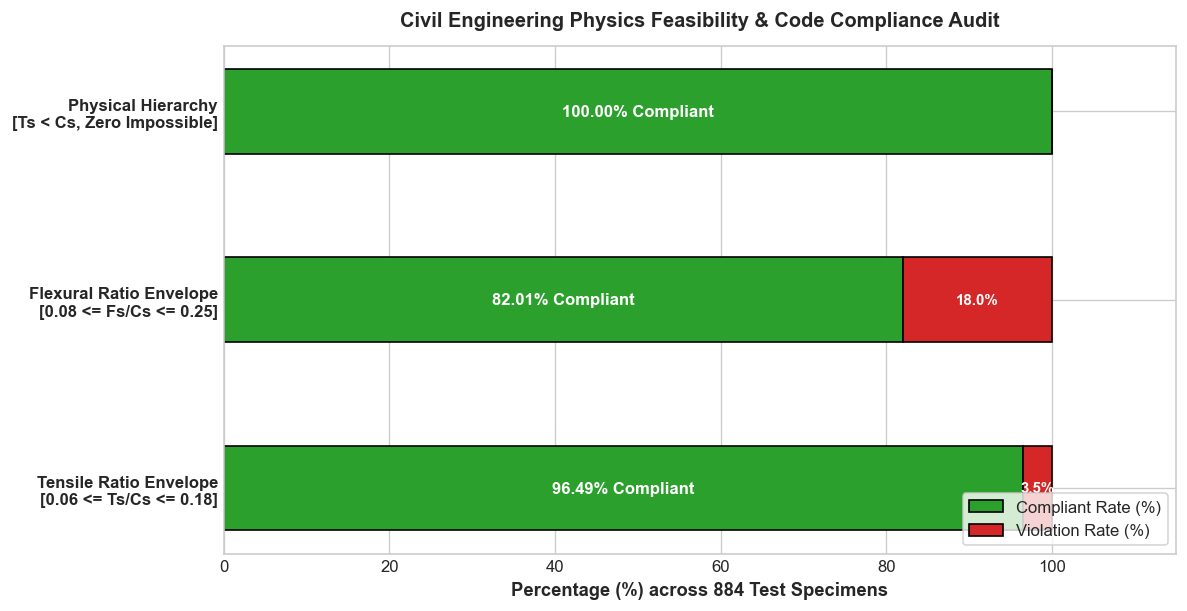

[SAVED] Physical compliance audit saved to: c:\Users\jeetu\projects\Capstone\3rdYearsem5\figures\13_physical_compliance_audit.png


In [34]:
# Plot 6: Physical Feasibility & Code Compliance Audit
pvr_rt = float(np.mean((pred_rt < 0.06) | (pred_rt > 0.18)) * 100.0)
pvr_rf = float(np.mean((pred_rf < 0.08) | (pred_rf > 0.25)) * 100.0)
pvr_impossible = float(np.mean(ts_pred_safe >= cs_pred_safe) * 100.0)

comp_rt = 100.0 - pvr_rt
comp_rf = 100.0 - pvr_rf
comp_imp = 100.0 - pvr_impossible

compliance_labels = [
    "Tensile Ratio Envelope\n[0.06 <= Ts/Cs <= 0.18]",
    "Flexural Ratio Envelope\n[0.08 <= Fs/Cs <= 0.25]",
    "Physical Hierarchy\n[Ts < Cs, Zero Impossible]"
]
comp_scores = [comp_rt, comp_rf, comp_imp]
viol_scores = [pvr_rt, pvr_rf, pvr_impossible]

fig, ax = plt.subplots(figsize=(10, 5.2))
y_pos = np.arange(len(compliance_labels))
h = 0.45

ax.barh(y_pos, comp_scores, height=h, label="Compliant Rate (%)", color="#2ca02c", edgecolor="black")
ax.barh(y_pos, viol_scores, left=comp_scores, height=h, label="Violation Rate (%)", color="#d62728", edgecolor="black")
ax.set_yticks(y_pos)
ax.set_yticklabels(compliance_labels, fontweight="bold", fontsize=10)
ax.set_xlabel("Percentage (%) across 884 Test Specimens", fontweight="bold")
ax.set_title("Civil Engineering Physics Feasibility & Code Compliance Audit", fontweight="bold", pad=12)
ax.set_xlim(0, 115)
ax.legend(loc="lower right", frameon=True)

for i in range(len(compliance_labels)):
    ax.text(comp_scores[i] / 2, i, f"{comp_scores[i]:.2f}% Compliant", va="center", ha="center", color="white", fontweight="bold", fontsize=10)
    if viol_scores[i] > 0.5:
        ax.text(comp_scores[i] + (viol_scores[i] / 2), i, f"{viol_scores[i]:.1f}%", va="center", ha="center", color="white", fontweight="bold", fontsize=9)

plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "13_physical_compliance_audit.png")
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"[SAVED] Physical compliance audit saved to: {fig_path}")


## 9. Final Quantitative Evaluation & Results CSV Persistence
In this final stage:
1. We assemble the formal quantitative performance metrics table ($R^2$, RMSE, MAE, coverage %, observed counts) and physical feasibility rates.
2. We export the quantitative summary into `final_evaluation_results.csv` (and copy to root directory).
3. We compile specimen-level predictions alongside ground truth measurements, residuals, and calculated ratios for all 884 unseen test specimens, exporting to `final_test_predictions.csv`.
4. We generate and update the formal text validation report `results.txt`.


In [35]:
# 1. Compile Final Evaluation Metrics Table
final_metrics_rows = []
for i, col in enumerate(TARGET_COLS):
    valid_idx = mask_test[:, i] == 1.0
    n_obs = int(valid_idx.sum())
    cov_pct = (n_obs / len(test_df)) * 100.0
    y_true = y_test_raw[valid_idx, i]
    y_pred = test_preds_raw[valid_idx, i]
    
    r2 = r2_score(y_true, y_pred)
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    mae = float(mean_absolute_error(y_true, y_pred))
    
    final_metrics_rows.append({
        "Target": col,
        "Property Name": "Compressive Strength" if col == "Cs_Mpa" else ("Splitting Tensile" if col == "Ts_Mpa" else "Flexural Strength"),
        "Observed_N": n_obs,
        "Total_Test_N": len(test_df),
        "Coverage_Pct": round(cov_pct, 2),
        "R2_Score": round(r2, 4),
        "RMSE_MPa": round(rmse, 4),
        "MAE_MPa": round(mae, 4)
    })

metrics_summary_df = pd.DataFrame(final_metrics_rows)

print("=" * 78)
print("            PIM-MTL FINAL TEST SET QUANTITATIVE EVALUATION RESULTS")
print("=" * 78)
display(metrics_summary_df)

print("\n--- Physical Feasibility & Constraint Audit ---")
print(f"1. Tensile Ratio Compliance [0.06 <= Ts/Cs <= 0.18]   : Violation = {pvr_rt:.2f}% | Compliance = {100-pvr_rt:.2f}%")
print(f"2. Flexural Ratio Compliance [0.08 <= Fs/Cs <= 0.25]  : Violation = {pvr_rf:.2f}% | Compliance = {100-pvr_rf:.2f}%")
print(f"3. Physically Impossible Preds (Ts >= Cs)             : Violation = {pvr_impossible:.2f}% | Compliance = {100-pvr_impossible:.2f}%")
print("=" * 78)

# 2. Save Final Evaluation Metrics to CSV
csv_metrics_path1 = os.path.join(RESULTS_DIR, "final_evaluation_results.csv")
csv_metrics_path2 = os.path.join(project_root, "final_evaluation_results.csv")
metrics_summary_df.to_csv(csv_metrics_path1, index=False)
metrics_summary_df.to_csv(csv_metrics_path2, index=False)
print(f"[SAVED] Final evaluation metrics successfully saved to CSV:")
print(f"        -> {csv_metrics_path1}")
print(f"        -> {csv_metrics_path2}")

# 3. Compile and Save Specimen-Level Test Predictions to CSV
predictions_df = pd.DataFrame({
    "Test_Index": np.arange(len(test_df)),
    "True_Cs_Mpa": y_test_raw[:, 0],
    "Pred_Cs_Mpa": test_preds_raw[:, 0],
    "Residual_Cs_Mpa": test_preds_raw[:, 0] - y_test_raw[:, 0],
    "True_Ts_Mpa": y_test_raw[:, 1],
    "Pred_Ts_Mpa": test_preds_raw[:, 1],
    "Residual_Ts_Mpa": test_preds_raw[:, 1] - y_test_raw[:, 1],
    "True_Fs_Mpa": y_test_raw[:, 2],
    "Pred_Fs_Mpa": test_preds_raw[:, 2],
    "Residual_Fs_Mpa": test_preds_raw[:, 2] - y_test_raw[:, 2],
    "Pred_Rt_Ts_over_Cs": pred_rt,
    "Pred_Rf_Fs_over_Cs": pred_rf,
    "Physically_Valid": (pred_rt >= 0.06) & (pred_rt <= 0.18) & (pred_rf >= 0.08) & (pred_rf <= 0.25) & (ts_pred_safe < cs_pred_safe)
})

csv_preds_path1 = os.path.join(RESULTS_DIR, "final_test_predictions.csv")
csv_preds_path2 = os.path.join(project_root, "final_test_predictions.csv")
predictions_df.to_csv(csv_preds_path1, index=False)
predictions_df.to_csv(csv_preds_path2, index=False)
print(f"[SAVED] Specimen-level test predictions successfully saved to CSV:")
print(f"        -> {csv_preds_path1}")
print(f"        -> {csv_preds_path2}")

# 4. Save Text Validation Report (results.txt)
results_txt_path = os.path.join(project_root, "results.txt")
with open(results_txt_path, "w", encoding="utf-8") as f:
    f.write("=" * 70 + "\n")
    f.write("      PIM-MTL CONCRETE STRENGTH PREDICTION PIPELINE RESULTS\n")
    f.write("=" * 70 + "\n\n")
    f.write(f"Total Test Specimens: {len(test_df)}\n")
    f.write(f"Compute Device      : {device}\n\n")
    f.write("--- Quantitative Accuracy Metrics ---\n")
    f.write(f"{'Target':<10} | {'Observed N':<10} | {'Coverage':<10} | {'R2 Score':<10} | {'RMSE (MPa)':<12} | {'MAE (MPa)':<10}\n")
    f.write("-" * 70 + "\n")
    for row in final_metrics_rows:
        f.write(f"{row['Target']:<10} | {row['Observed_N']:<10} | {row['Coverage_Pct']:>8.1f}% | {row['R2_Score']:>9.4f}  | {row['RMSE_MPa']:>10.4f}   | {row['MAE_MPa']:>8.4f}\n")
    f.write("-" * 70 + "\n\n")
    f.write("--- Physical Feasibility Audit ---\n")
    f.write(f"Tensile Ratio Violations (Rt outside [0.06, 0.18])  : {pvr_rt:.2f}%\n")
    f.write(f"Flexural Ratio Violations (Rf outside [0.08, 0.25]) : {pvr_rf:.2f}%\n")
    f.write(f"Physically Impossible Predictions (Ts >= Cs)        : {pvr_impossible:.2f}%\n\n")
    f.write("=" * 70 + "\n")

print(f"[SAVED] Comprehensive text report saved to: {results_txt_path}")
print("\nAll pipeline artifacts (model, preprocessor, figures, and CSV files) are verified and up to date!")


            PIM-MTL FINAL TEST SET QUANTITATIVE EVALUATION RESULTS


,Target,Property Name,Observed_N,Total_Test_N,Coverage_Pct,R2_Score,RMSE_MPa,MAE_MPa
0,Cs_Mpa,Compressive Strength,884,884,100.00,0.9818,1.3143,0.9931
1,Ts_Mpa,Splitting Tensile,696,884,78.73,0.9857,0.1097,0.0820
2,Fs_Mpa,Flexural Strength,363,884,41.06,0.9972,0.1262,0.0990



--- Physical Feasibility & Constraint Audit ---
1. Tensile Ratio Compliance [0.06 <= Ts/Cs <= 0.18]   : Violation = 3.51% | Compliance = 96.49%
2. Flexural Ratio Compliance [0.08 <= Fs/Cs <= 0.25]  : Violation = 17.99% | Compliance = 82.01%
3. Physically Impossible Preds (Ts >= Cs)             : Violation = 0.00% | Compliance = 100.00%
[SAVED] Final evaluation metrics successfully saved to CSV:
        -> c:\Users\jeetu\projects\Capstone\3rdYearsem5\results\final_evaluation_results.csv
        -> c:\Users\jeetu\projects\Capstone\3rdYearsem5\final_evaluation_results.csv
[SAVED] Specimen-level test predictions successfully saved to CSV:
        -> c:\Users\jeetu\projects\Capstone\3rdYearsem5\results\final_test_predictions.csv
        -> c:\Users\jeetu\projects\Capstone\3rdYearsem5\final_test_predictions.csv
[SAVED] Comprehensive text report saved to: c:\Users\jeetu\projects\Capstone\3rdYearsem5\results.txt

All pipeline artifacts (model, preprocessor, figures, and CSV files) are verifie